# German Electricity Demand Forecasting

Name: Srikanth Pasunoori

## 1. Dependencies

The package setup supplies the libraries used throughout the analysis. It also limits numerical-library threads for the model search.


In [1]:
# This cell loads or installs the required packages.
import importlib.util
import os
import subprocess
import sys

os.environ.setdefault("TF_CPP_MIN_LOG_LEVEL", "3")
for variable in ("OPENBLAS_NUM_THREADS", "MKL_NUM_THREADS", "OMP_NUM_THREADS"):
    os.environ[variable] = "1"
packages = {
    "numpy": "numpy>=1.26,<3",
    "pandas": "pandas>=2.1,<3",
    "scipy": "scipy>=1.11,<2",
    "matplotlib": "matplotlib>=3.8,<4",
    "sklearn": "scikit-learn>=1.4,<2",
    "statsmodels": "statsmodels>=0.14.6,<0.16",
    "threadpoolctl": "threadpoolctl>=3,<4",
    "requests": "requests>=2.31,<3",
    "holidays": "holidays>=0.50,<1",
    "joblib": "joblib>=1.3,<2",
    "tensorflow": "tensorflow>=2.16,<3",
}
missing = [requirement for module, requirement in packages.items()
           if importlib.util.find_spec(module) is None]
if missing:
    subprocess.run([sys.executable, "-m", "pip", "install", "--quiet", *missing],
                   check=True, stdout=subprocess.DEVNULL, stderr=subprocess.PIPE)

## 2. Configuration

Shared settings keep the forecast horizons, seasonal periods, and output paths consistent. A fixed seed supports reproducibility.


In [2]:
# This cell sets up imports, settings, and output folders.
import ast
import gc
import hashlib
import itertools
import json
import math
import random
import shutil
import time
import warnings
import zipfile
from dataclasses import dataclass
from importlib.metadata import PackageNotFoundError, version
from pathlib import Path

import holidays
import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import requests
from IPython.display import display
from scipy import stats
from sklearn.base import clone
from sklearn.ensemble import GradientBoostingRegressor, RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error
from sklearn.model_selection import ParameterSampler
from sklearn.preprocessing import StandardScaler
from threadpoolctl import threadpool_limits
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.stats.diagnostic import acorr_ljungbox
from statsmodels.tsa.seasonal import seasonal_decompose
from statsmodels.tsa.statespace.sarimax import SARIMAX, SARIMAXResults
from statsmodels.tsa.stattools import adfuller, kpss

@dataclass(frozen=True)
class Settings:
    """Stores the data paths and experiment settings."""
    seed: int = 42
    first_day: str = "2015-01-01"
    last_day: str = "2020-10-31 23:00:00"
    load_field: str = "DE_load_actual_entsoe_transparency"
    week_rule: str = "W-SUN"
    annual_weeks: int = 52
    hourly_week: int = 168
    search_iterations: int = 60
    seasonal_shortlist_per_d: int = 2
    tree_folds: int = 4
    validation_weeks: int = 13
    lstm_epochs: int = 30
    lstm_patience: int = 6
    bootstrap_draws: int = 1000
    source_url: str = "https://data.open-power-system-data.org/time_series/2020-10-06/time_series_60min_singleindex.csv"

cfg = Settings()
run_started = time.monotonic()
random.seed(cfg.seed)
np.random.seed(cfg.seed)
base = Path("/kaggle/working") if Path("/kaggle/working").exists() else Path.cwd()
project = base / "german_demand_study"
paths = {name: project / name for name in ("data", "tables", "figures", "models", "checkpoints")}
for folder in paths.values():
    folder.mkdir(parents=True, exist_ok=True)
plt.rcParams.update({"font.size": 12, "figure.dpi": 110})

## 3. Common tools

Common helpers keep metrics, timestamps, plots, and exports consistent across model families. The forecast store checks the alignment of each prediction.


In [3]:
# This cell defines helpers for scores, plots, and forecasts storage.
def write_table(frame, name, index=False):
    """Saves a table as CSV and returns the original table."""
    frame.to_csv(paths["tables"] / f"{name}.csv", index=index)
    return frame


def save_figure(name):
    """Saves, displays, and closes the current figure."""
    plt.tight_layout()
    plt.savefig(paths["figures"] / f"{name}.png", dpi=250, bbox_inches="tight")
    plt.show()
    plt.close()


def error_scores(actual, prediction, history, period):
    """Computes RMSE, MAE, MAPE, sMAPE and MASE on matching timestamps. MASE uses the training series at the given seasonal lag. MAPE is undefined when any actual value is zero."""
    if not actual.index.equals(prediction.index):
        raise ValueError("Forecast timestamps do not match observations")
    y, p = actual.to_numpy(float), prediction.to_numpy(float)
    if not np.isfinite(y).all() or not np.isfinite(p).all():
        raise ValueError("Evaluation contains non-finite values")
    scale = np.mean(np.abs(history.to_numpy(float)[period:] - history.to_numpy(float)[:-period]))
    denominator = np.abs(y) + np.abs(p)
    ratios = np.divide(np.abs(y - p), denominator, out=np.zeros_like(y), where=denominator > 0)
    return {"RMSE": float(np.sqrt(mean_squared_error(y, p))),
            "MAE": float(mean_absolute_error(y, p)),
            "MAPE_percent": float(100 * np.mean(np.abs((y - p) / y))) if np.all(y != 0) else np.nan,
            "sMAPE_percent": float(200 * ratios.mean()),
            "MASE": float(np.mean(np.abs(y - p)) / scale) if scale > 0 else np.nan}


class ForecastBook:
    """Stores aligned forecasts and intervals for one evaluation frequency."""
    def __init__(self, actual, training, period, frequency):
        """Sets the evaluation series and initializes forecast storage."""
        self.actual = actual
        self.training = training
        self.period = period
        self.frequency = frequency
        self.predictions = {}
        self.intervals = {}
        self.protocols = {}

    def add(self, name, prediction, protocol, interval=None):
        """Checks and stores a forecast and its optional interval."""
        if isinstance(prediction, pd.Series) and not prediction.index.equals(self.actual.index):
            raise ValueError("Forecast timestamps do not match the evaluation index")
        values = pd.Series(np.asarray(prediction, dtype=float), index=self.actual.index, name=name)
        error_scores(self.actual, values, self.training, self.period)
        self.predictions[name] = values
        self.protocols[name] = protocol
        if interval is not None:
            bounds = pd.DataFrame(np.asarray(interval, dtype=float), index=self.actual.index,
                                  columns=["lower", "upper"])
            if not np.isfinite(bounds.to_numpy()).all() or (bounds.lower > bounds.upper).any():
                raise ValueError("Invalid prediction interval")
            self.intervals[name] = bounds

    def scores(self, benchmark):
        """Scores forecasts and compares their RMSE with the chosen benchmark."""
        rows = [{"Model": name, "Frequency": self.frequency,
                 "Protocol": self.protocols[name], "N": len(self.actual),
                 **error_scores(self.actual, values, self.training, self.period)}
                for name, values in self.predictions.items()]
        result = pd.DataFrame(rows)
        reference = result.set_index("Model").loc[benchmark, "RMSE"]
        result["RMSE_improvement_percent"] = 100 * (reference - result.RMSE) / reference
        return result.sort_values("RMSE").reset_index(drop=True)

    def export(self, name):
        """Saves observations and predictions in one timestamped table."""
        frame = pd.DataFrame({"actual_MW": self.actual, **self.predictions})
        frame.rename_axis("timestamp").to_csv(paths["tables"] / f"{name}_predictions.csv")
        return frame


## 4. Load data

Complete hourly groups provide comparable daily and weekly load summaries. The final two years form a common holdout at both forecast frequencies.


In [4]:
# This cell loads German demand and splits the hourly and weekly data.
def obtain_load(settings):
    """Loads the German demand series and records data quality."""
    cache = paths["data"] / "source_load.csv"
    candidates = sorted(Path("/kaggle/input").rglob("time_series_60min_singleindex.csv")) if Path("/kaggle/input").exists() else []
    local = Path("time_series_60min_singleindex.csv")
    if local.is_file():
        candidates.insert(0, local)
    source = cache if cache.exists() else (candidates[0] if len(candidates) == 1 else settings.source_url)
    if not cache.exists() and len(candidates) > 1:
        raise ValueError("Multiple electricity source files found")
    data = pd.read_csv(source, usecols=["utc_timestamp", settings.load_field])
    data.to_csv(cache, index=False)
    index = pd.to_datetime(data.utc_timestamp, utc=True, errors="raise").dt.tz_localize(None)
    series = pd.Series(pd.to_numeric(data[settings.load_field], errors="coerce").to_numpy(), index=index)
    series = series.sort_index().loc[settings.first_day:settings.last_day]
    duplicates = int(series.index.duplicated().sum())
    series = series.loc[~series.index.duplicated(keep="last")]
    if series.first_valid_index() is None:
        raise ValueError("No German load observations available")
    series = series.loc[settings.first_day:series.last_valid_index()]
    hours = pd.date_range(pd.Timestamp(settings.first_day), series.index.max(), freq="h")
    observed = series.reindex(hours).rename("load_MW")
    clean = observed.copy()
    for lag in (settings.hourly_week, 24):
        clean = clean.fillna(clean.shift(lag))
    clean = clean.ffill(limit=3)
    if clean.isna().any() or (clean < 0).any():
        raise ValueError("Load data contain unresolved missing or negative values")
    audit = pd.DataFrame({"original_MW": observed, "clean_MW": clean,
                          "imputed": observed.isna()})
    audit.rename_axis("timestamp").to_csv(paths["data"] / "load_audit.csv")
    return clean.rename("load_MW"), observed, duplicates


def complete_means(series, rule, count):
    """Averages groups that contain the expected number of observations."""
    grouped = series.resample(rule)
    return grouped.mean().where(grouped.count().eq(count)).dropna()


load, raw_load, duplicate_rows = obtain_load(cfg)
daily = complete_means(load, "D", 24)
weekly = complete_means(load, cfg.week_rule, cfg.hourly_week)
origin = load.index.max().normalize() - pd.DateOffset(years=2) + pd.Timedelta(days=1)
hour_train, hour_test = load.loc[load.index < origin], load.loc[load.index >= origin]
week_train = weekly.loc[weekly.index < origin]
week_test = weekly.loc[weekly.index - pd.Timedelta(days=6) >= origin]
if raw_load.reindex(hour_test.index).isna().any():
    raise ValueError("Test observations must not be imputed")
if len(week_train) < 3 * cfg.annual_weeks or len(week_test) < 100:
    raise ValueError("Insufficient complete weeks for the required experiment")
weekly_book = ForecastBook(week_test, week_train, cfg.annual_weeks, "Weekly")
hourly_book = ForecastBook(hour_test, hour_train, cfg.hourly_week, "Hourly")
for name, values in {"hourly": load, "daily": daily, "weekly": weekly}.items():
    values.rename_axis("timestamp").to_csv(paths["data"] / f"load_{name}.csv")
quality = pd.DataFrame([{"Start": load.index.min(), "End": load.index.max(),
                         "Hourly_rows": len(load), "Daily_rows": len(daily),
                         "Weekly_rows": len(weekly), "Imputed_hours": int(raw_load.isna().sum()),
                         "Duplicate_rows": duplicate_rows, "Forecast_origin": origin,
                         "Test_hours": len(hour_test), "Test_weeks": len(week_test)}])
display(write_table(quality, "data_quality"))


,Start,End,Hourly_rows,Daily_rows,Weekly_rows,Imputed_hours,Duplicate_rows,Forecast_origin,Test_hours,Test_weeks
0,2015-01-01,2020-09-30 23:00:00,50400,2100,299,0,0,2018-10-01,17544,104


## 5. Exploratory analysis

Profiles and decomposition separate recurring load patterns from longer-term movement. They provide evidence for an annual seasonal period.


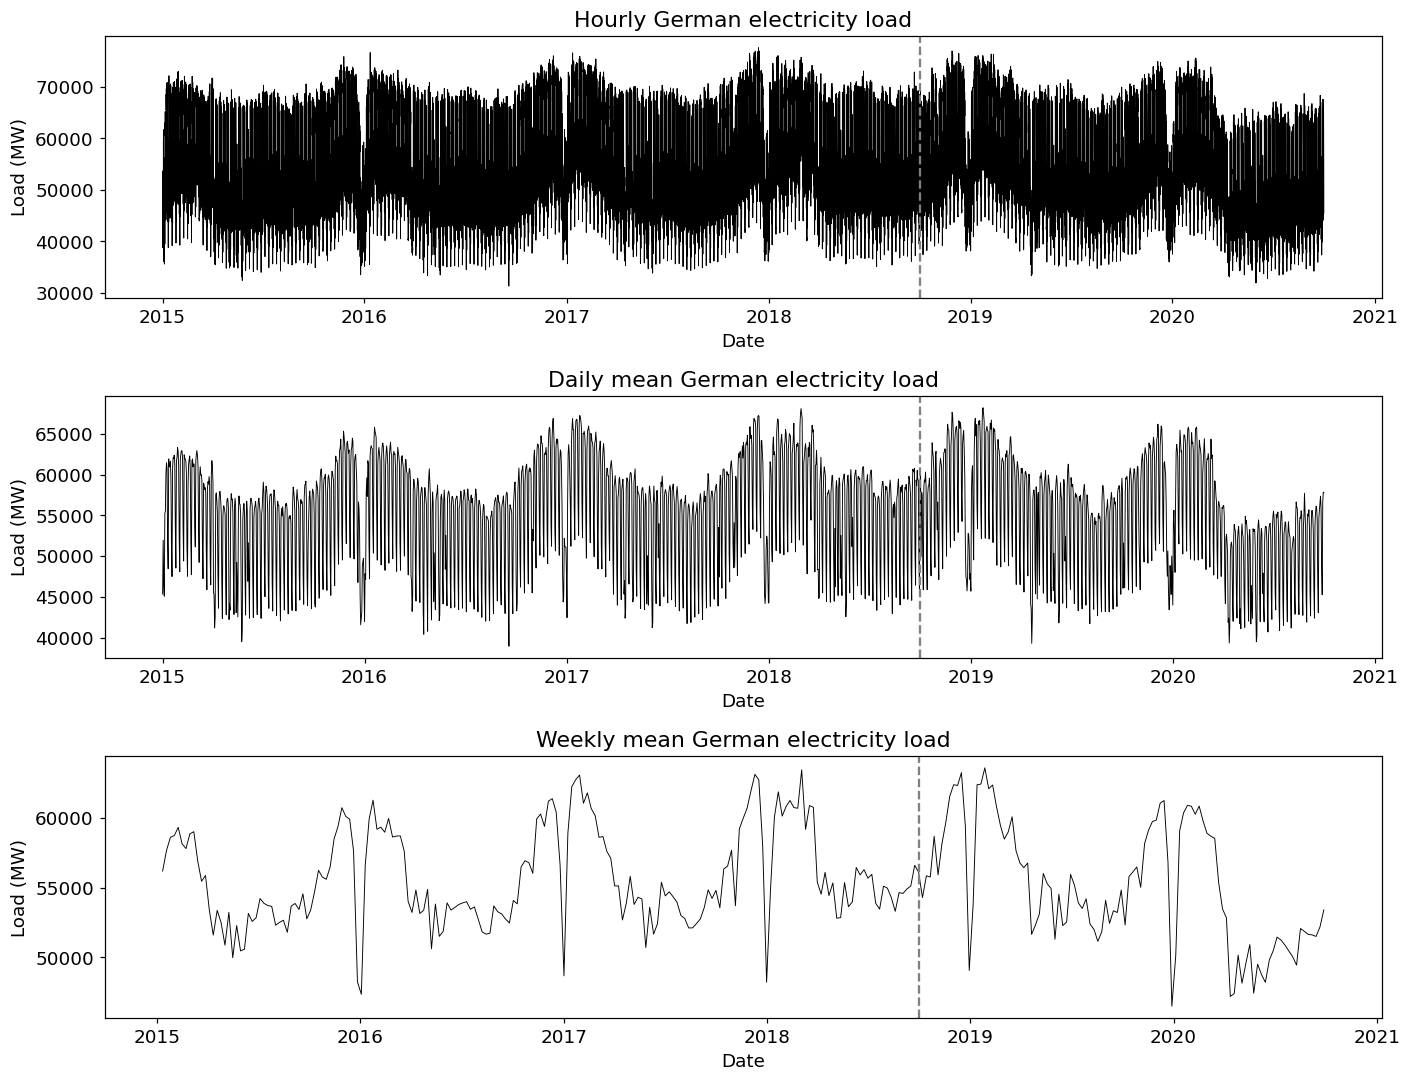

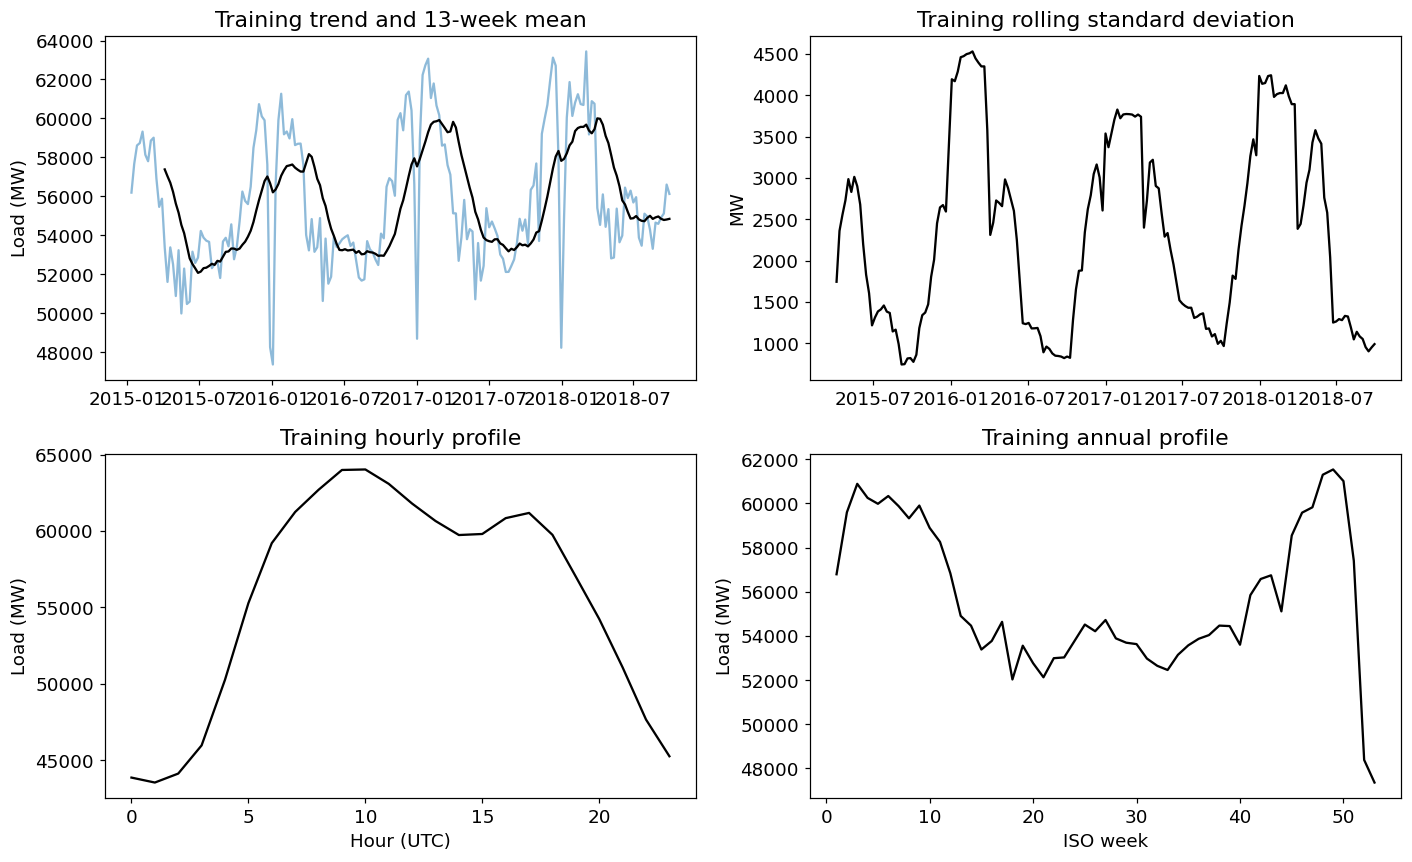

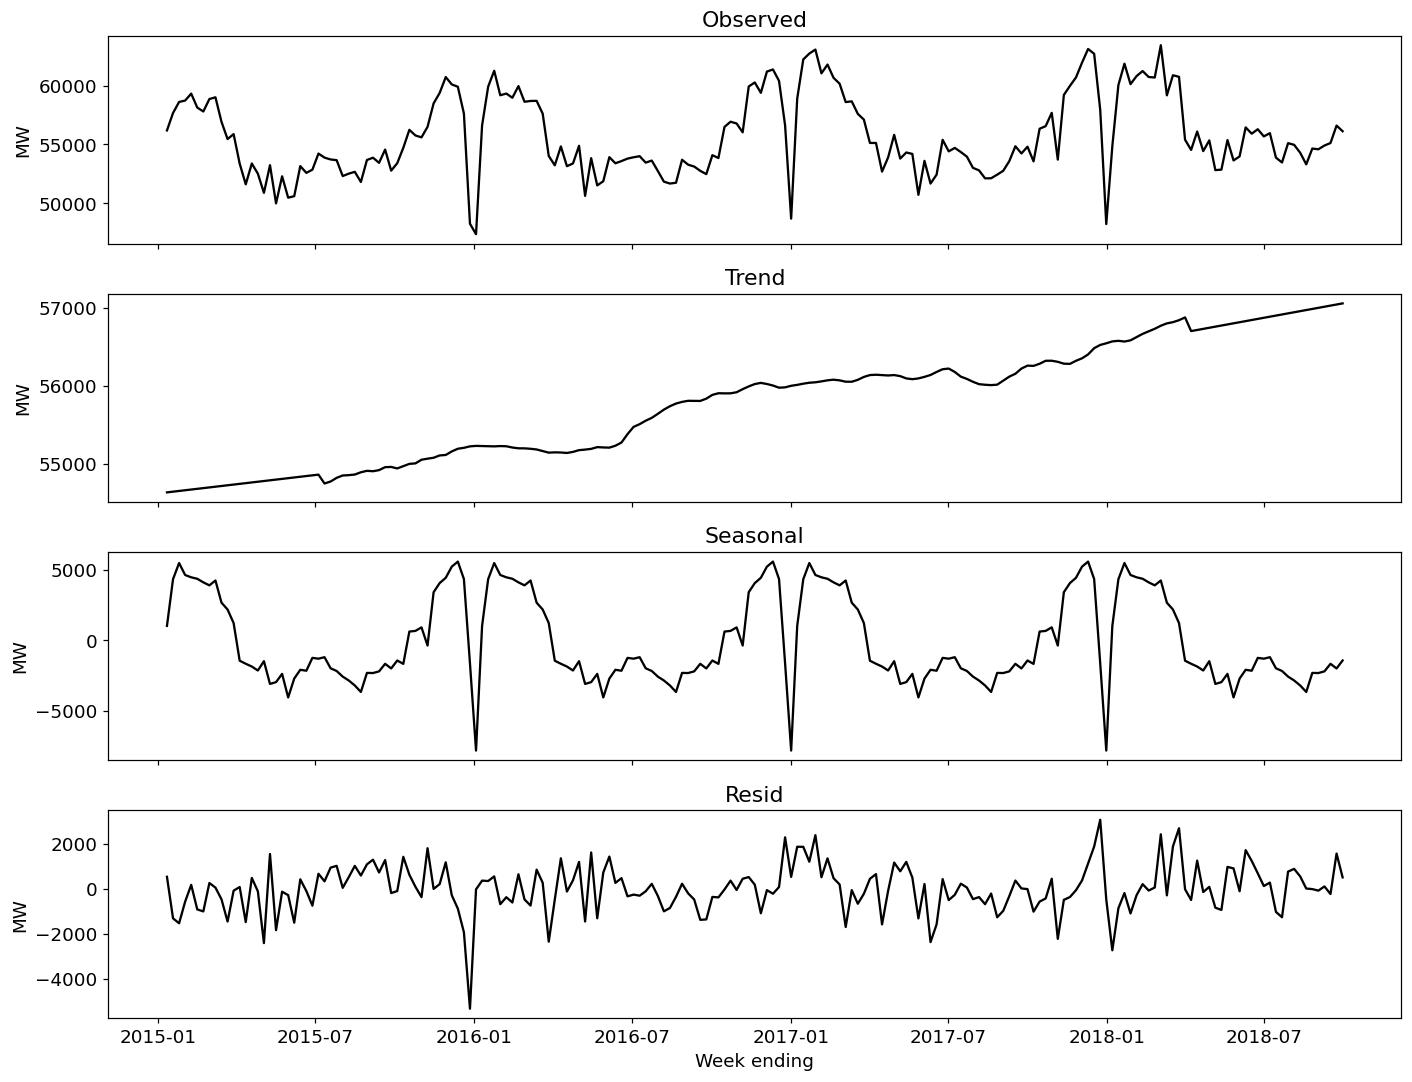

,Weekly_training_MW
count,195.000000
mean,55700.700458
std,3345.732331
min,47364.035714
25%,53390.044643
50%,54858.434524
75%,58622.514881
max,63442.005952


In [5]:
# This cell plots demand patterns and decomposes weekly demand.
fig, axes = plt.subplots(3, 1, figsize=(13, 10))
for ax, values, label in zip(axes, (load, daily, weekly), ("Hourly", "Daily mean", "Weekly mean")):
    ax.plot(values.index, values, color="black", linewidth=0.6)
    ax.axvline(origin, color="gray", linestyle="--")
    ax.set(title=f"{label} German electricity load", ylabel="Load (MW)", xlabel="Date")
save_figure("01_load_overview")

fig, axes = plt.subplots(2, 2, figsize=(13, 8))
axes[0, 0].plot(week_train.index, week_train, alpha=0.5)
axes[0, 0].plot(week_train.rolling(13).mean(), color="black")
axes[0, 0].set(title="Training trend and 13-week mean", ylabel="Load (MW)")
axes[0, 1].plot(week_train.rolling(13).std(), color="black")
axes[0, 1].set(title="Training rolling standard deviation", ylabel="MW")
hour_train.groupby(hour_train.index.hour).mean().plot(ax=axes[1, 0], color="black")
axes[1, 0].set(title="Training hourly profile", xlabel="Hour (UTC)", ylabel="Load (MW)")
week_train.groupby(week_train.index.isocalendar().week).mean().plot(ax=axes[1, 1], color="black")
axes[1, 1].set(title="Training annual profile", xlabel="ISO week", ylabel="Load (MW)")
save_figure("02_training_patterns")

parts = seasonal_decompose(week_train, model="additive", period=cfg.annual_weeks,
                           extrapolate_trend=cfg.annual_weeks - 1)
fig, axes = plt.subplots(4, 1, figsize=(13, 10), sharex=True)
for ax, name in zip(axes, ("observed", "trend", "seasonal", "resid")):
    ax.plot(getattr(parts, name), color="black")
    ax.set(ylabel="MW", title=name.capitalize())
axes[-1].set_xlabel("Week ending")
save_figure("03_decomposition")
write_table(week_train.describe().to_frame("Weekly_training_MW"), "training_summary", index=True)


## 6. Stationarity

Unit-root tests and autocorrelation plots describe the weekly series before and after differencing. These checks inform the candidate model orders.


,Series,ADF_statistic,ADF_p,KPSS_statistic,KPSS_p,ADF_reject_unit_root,KPSS_reject_stationarity
0,Level,-5.003027,2.188904e-05,0.149877,0.1,True,False
1,First difference,-5.570781,1.469164e-06,0.040588,0.1,True,False
2,Seasonal difference,-5.039514,1.852536e-05,0.090992,0.1,True,False
3,Combined difference,-6.727919,3.352826e-09,0.013846,0.1,True,False


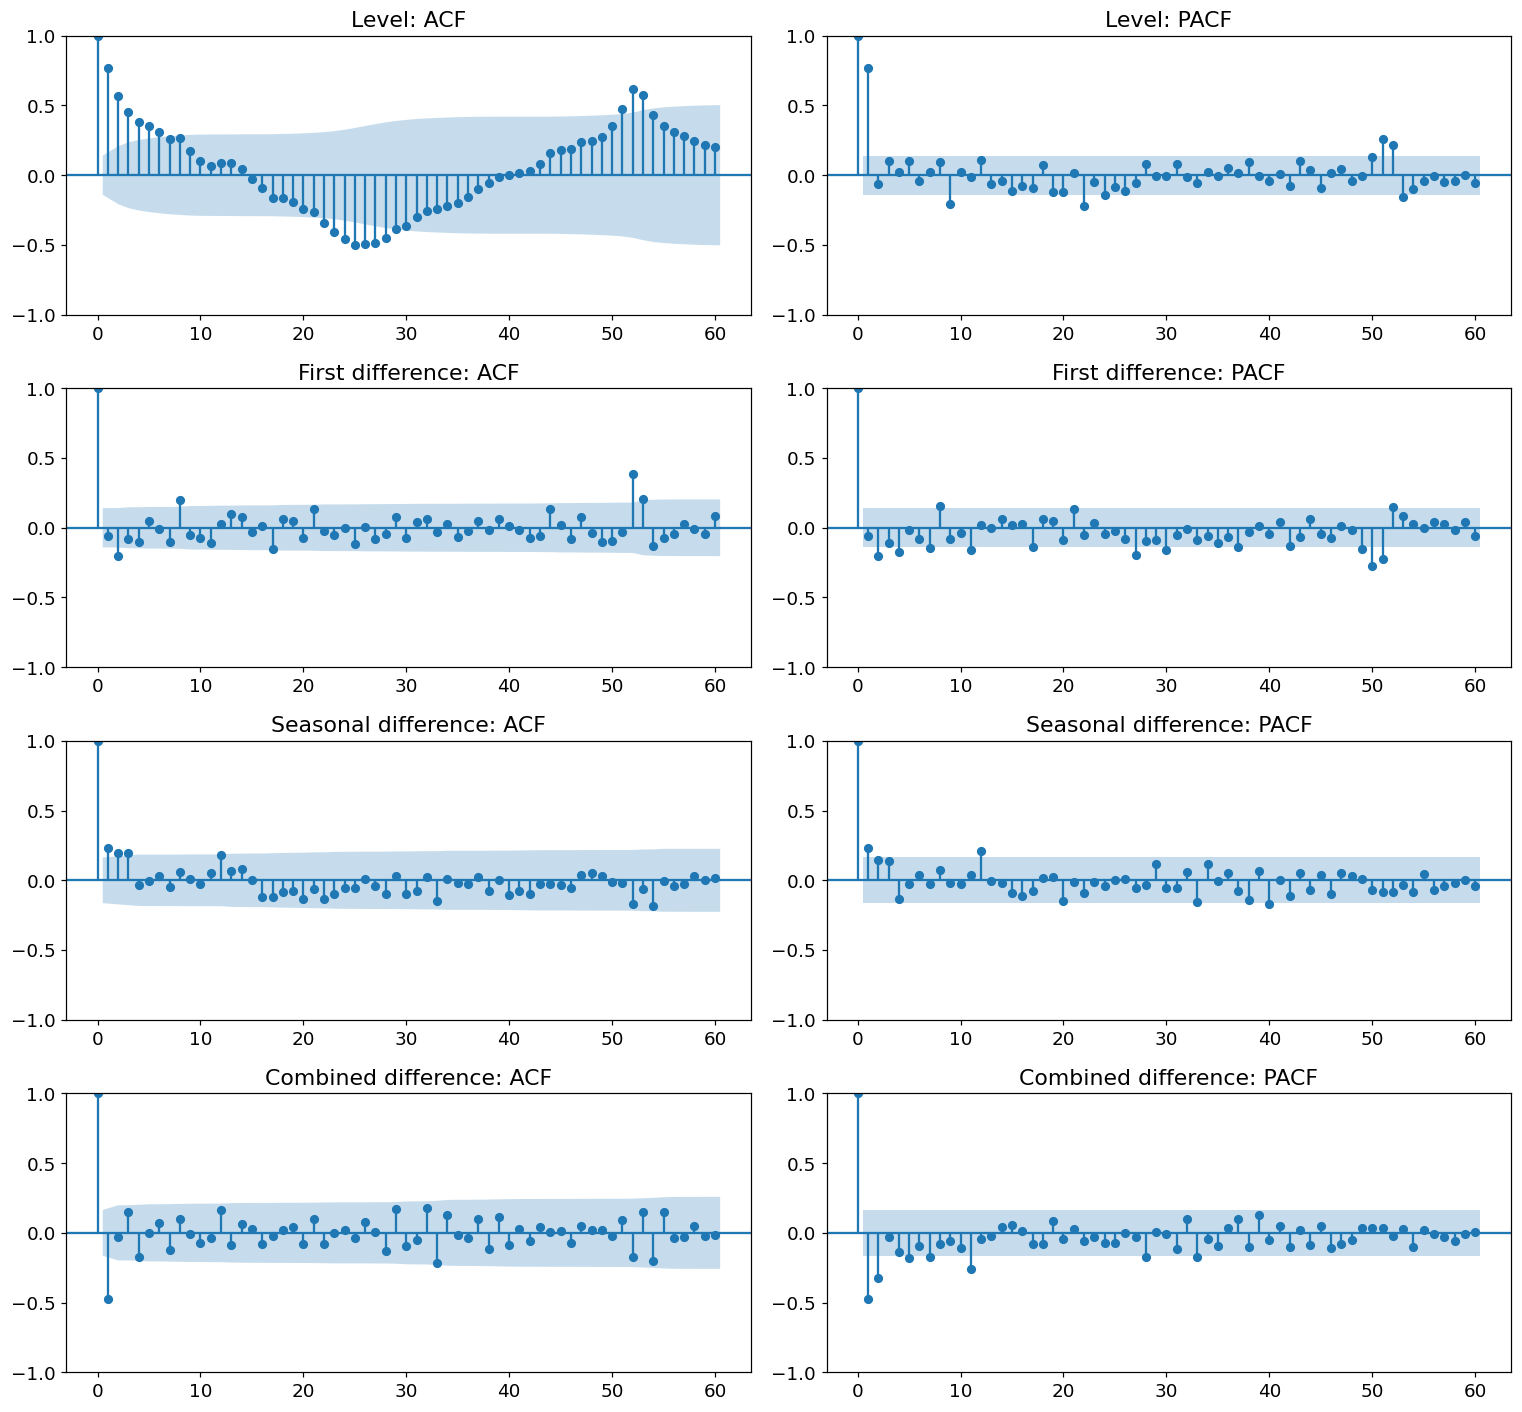

In [6]:
# This cell tests stationarity and plots autocorrelations.
def stationarity_tests(series, name):
    """Reports ADF and KPSS results for a weekly series."""
    values = series.dropna()
    from inspect import signature

    adf_options = {"result_object": False} if "result_object" in signature(adfuller).parameters else {}
    adf = adfuller(values, autolag="AIC", **adf_options)
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        kp = kpss(values, regression="c", nlags="auto")
    return {"Series": name, "ADF_statistic": adf[0], "ADF_p": adf[1],
            "KPSS_statistic": kp[0], "KPSS_p": kp[1],
            "ADF_reject_unit_root": adf[1] < 0.05,
            "KPSS_reject_stationarity": kp[1] < 0.05}


transformations = {"Level": week_train, "First difference": week_train.diff(),
                   "Seasonal difference": week_train.diff(cfg.annual_weeks),
                   "Combined difference": week_train.diff().diff(cfg.annual_weeks)}
stationarity = pd.DataFrame([stationarity_tests(values, name)
                             for name, values in transformations.items()])
display(write_table(stationarity, "stationarity"))
fig, axes = plt.subplots(4, 2, figsize=(14, 13))
for row, (name, values) in enumerate(transformations.items()):
    clean = values.dropna()
    lags = min(60, len(clean) // 2 - 1)
    plot_acf(clean, lags=lags, ax=axes[row, 0])
    plot_pacf(clean, lags=lags, method="ywm", ax=axes[row, 1])
    axes[row, 0].set_title(f"{name}: ACF")
    axes[row, 1].set_title(f"{name}: PACF")
save_figure("04_stationarity_acf_pacf")


## 7. Benchmark forecasts

Simple forecasts establish the accuracy that more complex models need to beat. Seasonal naive measures the value of repeating the annual load cycle.


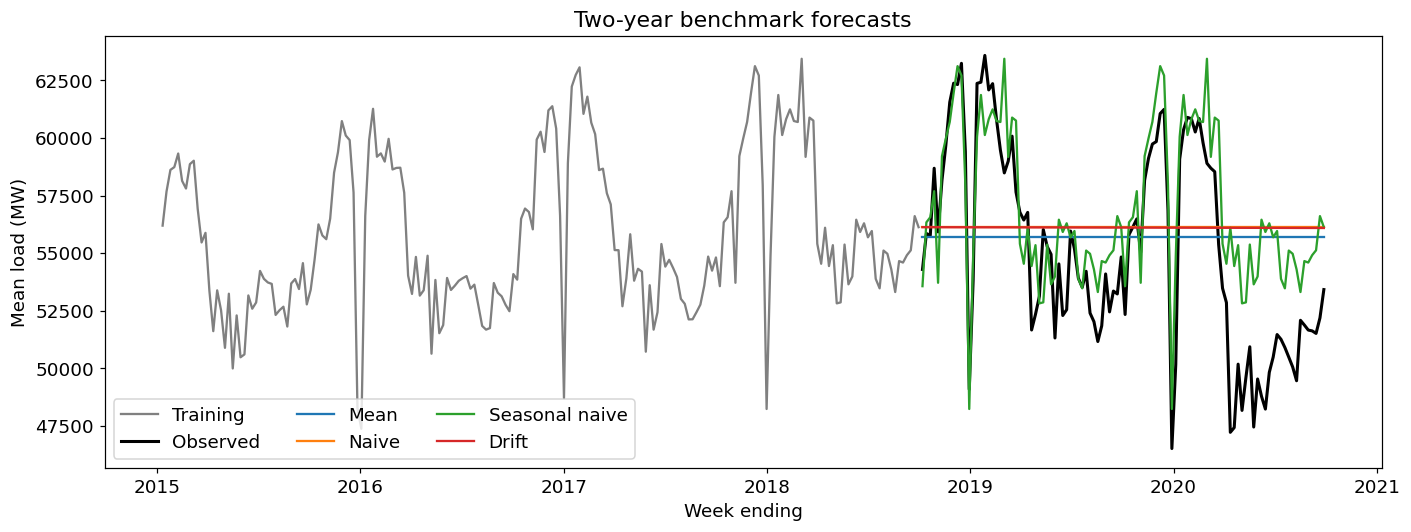

,Model,Frequency,Protocol,N,RMSE,MAE,MAPE_percent,sMAPE_percent,MASE,RMSE_improvement_percent
0,Seasonal naive,Weekly,Operational,104,2988.248349,2288.489240,4.356128,4.206690,1.693843,0.000000
1,Mean,Weekly,Operational,104,4402.058785,3789.845282,6.978857,6.873777,2.805083,-47.312347
2,Drift,Weekly,Operational,104,4466.494389,3850.775752,7.138611,6.982349,2.850181,-49.468647
3,Naive,Weekly,Operational,104,4475.767085,3858.147779,7.154389,6.995443,2.855638,-49.778953


In [7]:
# This cell generates and scores the benchmark forecasts.
def simple_forecasts(history, horizon, period):
    """Creates mean, naive, seasonal naive, and drift forecasts."""
    last = float(history.iloc[-1])
    slope = (last - float(history.iloc[0])) / (len(history) - 1)
    return {"Mean": np.full(horizon, history.mean()), "Naive": np.full(horizon, last),
            "Seasonal naive": np.resize(history.iloc[-period:].to_numpy(), horizon),
            "Drift": last + slope * np.arange(1, horizon + 1)}


for name, prediction in simple_forecasts(week_train, len(week_test), cfg.annual_weeks).items():
    weekly_book.add(name, prediction, "Operational")
fig, ax = plt.subplots(figsize=(13, 5))
ax.plot(week_train, color="gray", label="Training")
ax.plot(week_test, color="black", linewidth=2, label="Observed")
for name, prediction in weekly_book.predictions.items():
    ax.plot(prediction, label=name)
ax.set(title="Two-year benchmark forecasts", xlabel="Week ending", ylabel="Mean load (MW)")
ax.legend(ncol=3)
save_figure("05_benchmarks")
display(write_table(weekly_book.scores("Seasonal naive"), "benchmark_scores"))


## 8. SARIMA search engine

The search covers every required non-seasonal order and extends the strongest orders with seasonal terms. A common likelihood window supports fair AIC comparisons.


In [8]:
# This cell defines the SARIMA search and saves its progress.
search_orders = list(itertools.product(range(7), range(3), range(7)))
season_orders = [(p, d, q, cfg.annual_weeks) for p, d, q in itertools.product(range(2), repeat=3)]
common_burn = max(order[1] + seasonal[1] * seasonal[3]
                  for order, seasonal in itertools.product(search_orders, season_orders))


load_center = float(week_train.mean())
load_scale = float(week_train.std())
if not np.isfinite(load_scale) or load_scale <= 0:
    raise ValueError("Weekly training load must have positive variation")


def level_forecast(fitted, steps, exog=None):
    """Returns state-space predictions and validated intervals in MW."""
    prediction = fitted.get_forecast(steps=steps, exog=exog)
    mean = prediction.predicted_mean * load_scale + load_center
    bounds = prediction.conf_int(alpha=0.05) * load_scale + load_center
    variance = np.asarray(prediction.var_pred_mean)
    if (not np.isfinite(mean).all() or not np.isfinite(bounds.to_numpy()).all()
            or not np.isfinite(variance).all() or (variance <= 0).any()
            or (bounds.iloc[:, 0] >= bounds.iloc[:, 1]).any()):
        raise ValueError("Degenerate state-space forecast variance or interval")
    return mean, bounds


def fit_state_model(target, order, seasonal, exog=None, *, inference=False):
    """Fits a seasonal state-space model and checks convergence."""
    scaled = (target - load_center) / load_scale
    model = SARIMAX(scaled, exog=exog, order=order, seasonal_order=seasonal,
                    trend="n", enforce_stationarity=True, enforce_invertibility=True,
                    concentrate_scale=bool(order[0] or order[2] or seasonal[0] or seasonal[2]
                                           or exog is not None),
                    loglikelihood_burn=common_burn)
    failure = "Non-converged fit"
    solvers = ("lbfgs", "powell") if inference else ("lbfgs",)
    for solver in solvers:
        try:
            with threadpool_limits(limits=1), warnings.catch_warnings():
                warnings.simplefilter("ignore")
                result = model.fit(method=solver, maxiter=cfg.search_iterations, disp=False,
                                   cov_type="opg" if inference else "none",
                                   maxfun=1200 if solver == "powell" else 5000)
                contributions = result.llf_obs[common_burn:]
                if (result.mle_retvals.get("converged", False) and np.isfinite(result.aic)
                        and np.isfinite(result.params).all() and np.isfinite(result.scale)
                        and result.scale > 0 and np.isfinite(contributions).all()
                        and np.any(contributions != 0)):
                    if exog is None:
                        level_forecast(result, len(week_test))
                    return result, solver
        except (ValueError, RuntimeError, np.linalg.LinAlgError) as exc:
            failure = str(exc)
    raise RuntimeError(failure)


def sarima_candidates(rows):
    """Yields the non-seasonal grid and the shortlisted seasonal extensions."""
    baseline = (0, 0, 0, cfg.annual_weeks)
    for order in search_orders:
        yield order, baseline
    for d in range(3):
        eligible = [row for row in rows if row["success"] and row["order"][1] == d
                    and tuple(row["seasonal"]) == baseline]
        for row in sorted(eligible, key=lambda item: item["AIC"])[:cfg.seasonal_shortlist_per_d]:
            for seasonal in season_orders:
                if seasonal != baseline:
                    yield tuple(row["order"]), seasonal


def search_sarima(target):
    """Evaluates candidate orders and checkpoints the search results."""
    identity = {"data": hashlib.sha256(target.index.asi8.tobytes() + target.to_numpy(float).tobytes()).hexdigest(),
                "statsmodels": version("statsmodels"), "iterations": cfg.search_iterations,
                "burn": common_burn, "season": cfg.annual_weeks, "protocol": "scaled_staged_v2",
                "shortlist_per_d": cfg.seasonal_shortlist_per_d, "horizon": len(week_test)}
    key = hashlib.sha256(json.dumps(identity, sort_keys=True).encode()).hexdigest()[:16]
    checkpoint = paths["checkpoints"] / f"sarima_{key}.json"
    saved = json.loads(checkpoint.read_text()) if checkpoint.exists() else {"identity": identity, "rows": []}
    if saved["identity"] != identity:
        raise ValueError("Checkpoint configuration mismatch")
    completed = {(tuple(row["order"]), tuple(row["seasonal"])) for row in saved["rows"]}
    for order, seasonal in sarima_candidates(saved["rows"]):
        if (order, seasonal) in completed:
            continue
        row = {"order": order, "seasonal": seasonal, "AIC": None, "BIC": None,
               "log_likelihood": None, "effective_n": len(target) - common_burn,
               "burn_in": common_burn, "success": False, "solver": None, "error": None}
        try:
            fitted, solver = fit_state_model(target, order, seasonal)
            previous_best = min((item["AIC"] for item in saved["rows"] if item["success"]), default=np.inf)
            artifact = None
            if fitted.aic < previous_best:
                artifact = f"search_{key}_{len(saved['rows'])}.pickle"
                fitted.save(paths["models"] / artifact)
            row.update(AIC=float(fitted.aic), BIC=float(fitted.bic),
                       log_likelihood=float(fitted.llf), effective_n=int(fitted.nobs_effective),
                       success=True, solver=solver, artifact=artifact)
        except Exception as exc:
            row["error"] = str(exc)[:200]
        saved["rows"].append(row)
        if len(saved["rows"]) % 10 == 0:
            print(f"SARIMA candidates completed: {len(saved['rows'])}", flush=True)
        staged = checkpoint.with_suffix(".tmp")
        staged.write_text(json.dumps(saved, allow_nan=False))
        staged.replace(checkpoint)
        successful = [item for item in saved["rows"] if item["success"]]
        if successful:
            best_artifact = min(successful, key=lambda item: item["AIC"])["artifact"]
            for old_artifact in paths["models"].glob(f"search_{key}_*.pickle"):
                if old_artifact.name != best_artifact:
                    old_artifact.unlink()
    return pd.DataFrame(saved["rows"]), identity

## 9. SARIMA selection

Training AIC ranks the successful SARIMA candidates. The saved selection records which ordinary and seasonal orders were used.


In [ ]:
# This cell runs the search and selects the best valid SARIMA fit.
sarima_started = time.monotonic()
sarima_grid, search_identity = search_sarima(week_train)
print(f"SARIMA search elapsed this session: {(time.monotonic() - sarima_started) / 60:.1f} minutes")
write_table(sarima_grid, "sarima_search")
if len(sarima_grid) != len(list(sarima_candidates(sarima_grid.to_dict("records")))) or not sarima_grid.success.any():
    raise RuntimeError("The complete SARIMA search did not produce a valid fit")
ranking = sarima_grid.loc[sarima_grid.success].sort_values("AIC")
selected = ranking.iloc[0]
order = tuple(selected.order)
seasonal_order = tuple(selected.seasonal)
sarima = SARIMAXResults.load(paths["models"] / selected.artifact)
if not np.isclose(sarima.aic, selected.AIC):
    raise AssertionError("Saved SARIMA fit differs from the search result")
sarima.save(paths["models"] / "sarima_selected.pickle")
(paths["models"] / "state_load_scale.json").write_text(
    json.dumps({"center_MW": load_center, "scale_MW": load_scale}, indent=2)
)
selection = pd.DataFrame([{"order": str(order), "seasonal_order": str(seasonal_order),
                           "AIC": sarima.aic, "BIC": sarima.bic, "burn_in": common_burn,
                           "effective_n": sarima.nobs_effective}])
display(write_table(selection, "sarima_selected"))
family = ranking.assign(d=ranking.order.map(lambda x: x[1]),
                         D=ranking.seasonal.map(lambda x: x[1]))
display(write_table(family.groupby(["d", "D"], as_index=False).first()
                    [["d", "D", "order", "seasonal", "AIC", "effective_n"]], "differencing_comparison"))

SARIMA candidates completed: 10
SARIMA candidates completed: 20
SARIMA candidates completed: 30
SARIMA candidates completed: 40
SARIMA candidates completed: 50
SARIMA candidates completed: 60
SARIMA candidates completed: 70
SARIMA candidates completed: 80
SARIMA candidates completed: 90
SARIMA candidates completed: 100
SARIMA candidates completed: 110
SARIMA candidates completed: 120
SARIMA candidates completed: 130
SARIMA candidates completed: 140
SARIMA candidates completed: 150
SARIMA candidates completed: 160
SARIMA candidates completed: 170
SARIMA candidates completed: 180


## 10. Residuals and prediction intervals

Residual plots and tests show whether predictable structure remains after fitting. Prediction intervals quantify the model’s forecast uncertainty.


In [ ]:
# This cell checks SARIMA residuals and calculates prediction intervals.
def residual_diagnostics(fitted, name):
    """Returns training residuals and Ljung–Box test results."""
    residual = fitted.resid.iloc[common_burn:].dropna() * load_scale
    lags = [lag for lag in (1, 4, 12, 26, 52) if lag < len(residual)]
    table = acorr_ljungbox(residual, lags=lags, return_df=True).rename_axis("lag").reset_index()
    table.insert(0, "Model", name)
    return residual, table


residual, ljung = residual_diagnostics(sarima, "SARIMA")
display(write_table(ljung, "sarima_residual_tests"))
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
axes[0, 0].plot(residual, color="black")
axes[0, 0].set(title="Training residuals", ylabel="MW")
plot_acf(residual, lags=min(52, len(residual) - 1), ax=axes[0, 1])
axes[1, 0].hist(residual, bins=20, density=True, color="gray", edgecolor="black")
axes[1, 0].set(title="Residual distribution", xlabel="MW", ylabel="Density")
stats.probplot(residual, dist="norm", plot=axes[1, 1])
save_figure("06_sarima_residuals")
mean, bounds = level_forecast(sarima, len(week_test))
weekly_book.add("SARIMA", mean, "Operational", bounds)

## 11. Temperature and holidays

Temperature and holidays provide weather and calendar inputs. Training climatology gives an operational weather path available at the forecast origin.


In [ ]:
# This cell prepares weekly Berlin temperatures and German holidays.
def berlin_weather(first, last):
    """Loads or downloads daily Berlin temperatures for the requested dates."""
    file = paths["data"] / "berlin_daily.csv"
    wanted = pd.date_range(first, last, freq="D")
    if file.exists():
        values = pd.read_csv(file, index_col=0, parse_dates=True).iloc[:, 0]
    else:
        response = requests.get("https://archive-api.open-meteo.com/v1/archive",
                                params={"latitude": 52.52, "longitude": 13.41,
                                        "start_date": str(first.date()), "end_date": str(last.date()),
                                        "daily": "temperature_2m_mean", "timezone": "UTC"}, timeout=90)
        response.raise_for_status()
        payload = response.json()["daily"]
        values = pd.Series(payload["temperature_2m_mean"], index=pd.to_datetime(payload["time"]),
                           name="temperature_C", dtype=float)
        values.rename_axis("date").to_csv(file)
    if not values.index.is_unique or not wanted.isin(values.index).all() or values.reindex(wanted).isna().any():
        raise ValueError("Temperature cache has incomplete daily coverage")
    return values.reindex(wanted)


def weather_normal(history, dates):
    """Maps training ISO-week temperature averages to future dates."""
    averages = history.groupby(history.index.isocalendar().week).mean()
    return pd.Series([averages.get(int(w), history.mean()) for w in dates.isocalendar().week],
                     index=dates, name="temperature_C", dtype=float)


weather_daily = berlin_weather(load.index.min().normalize(), load.index.max().normalize())
calendar = holidays.Germany(years=range(load.index.min().year, load.index.max().year + 1))
holiday_daily = pd.Series([float(day.date() in calendar) for day in weather_daily.index],
                           index=weather_daily.index)
external = pd.DataFrame({"temperature": weather_daily.resample(cfg.week_rule).mean(),
                          "holidays": holiday_daily.resample(cfg.week_rule).sum()}).reindex(weekly.index)
if external.isna().any().any():
    raise ValueError("Weekly covariates are incomplete")
weather_train = external.loc[week_train.index]
weather_test = external.loc[week_test.index]
normal_test = weather_normal(weather_train.temperature, week_test.index)
external.to_csv(paths["data"] / "weekly_covariates.csv")
write_table(pd.DataFrame([
    {"Variable": "Observed future temperature", "Known_at_origin": False, "Use": "Conditional"},
    {"Variable": "Training weather climatology", "Known_at_origin": True, "Use": "Operational proxy"},
    {"Variable": "National holiday calendar", "Known_at_origin": True, "Use": "Operational"},
]), "covariate_availability")
fig, ax = plt.subplots(figsize=(7, 5))
ax.scatter(weather_train.temperature, week_train, c=weather_train.holidays, cmap="Greys", edgecolor="black")
ax.set(xlabel="Berlin weekly temperature (C)", ylabel="Weekly mean load (MW)",
       title="Training temperature and electricity load")
save_figure("07_weather_load")


## 12. SARIMAX experiments

Matched SARIMAX fits help isolate the contribution of weather and holidays. The forecast scenarios distinguish operational and conditional inputs.


In [12]:
# This cell fits SARIMAX models and forecasts with different inputs.
state_scenarios = {
    "SARIMAX holidays": (["holidays"], None, "Operational"),
    "SARIMAX temperature": (["temperature"], weather_test.temperature, "Conditional"),
    "SARIMAX temperature + holidays": (["temperature", "holidays"], weather_test.temperature, "Conditional"),
    "SARIMAX climatology": (["temperature"], normal_test, "Operational"),
    "SARIMAX climatology + holidays": (["temperature", "holidays"], normal_test, "Operational"),
}
state_diagnostics = [ljung]
state_coefficients = []
state_columns = list(dict.fromkeys(tuple(columns) for columns, _, _ in state_scenarios.values()))
state_inputs = {}
for columns in state_columns:
    frame = weather_train[list(columns)]
    scaler = StandardScaler().fit(frame)
    state_inputs[columns] = (scaler, pd.DataFrame(scaler.transform(frame), index=frame.index, columns=frame.columns))

state_ranking = ranking.loc[
    ranking.order.map(lambda x: x[0] + x[2] <= 2)
    & ranking.seasonal.map(lambda x: 1 <= sum(x[:3]) and x[0] + x[2] <= 1)
]
state_attempts = []
for candidate in state_ranking.itertuples():
    state_order, state_seasonal = tuple(candidate.order), tuple(candidate.seasonal)
    try:
        matched, _ = fit_state_model(week_train, state_order, state_seasonal)
        state_fits = {}
        for key, (_, train_x) in state_inputs.items():
            fitted, _ = fit_state_model(week_train, state_order, state_seasonal, train_x, inference=True)
            level_forecast(fitted, len(week_test), np.zeros((len(week_test), train_x.shape[1])))
            state_fits[key] = fitted
    except (ValueError, RuntimeError) as exc:
        state_attempts.append({"order": state_order, "seasonal_order": state_seasonal, "status": str(exc)})
        continue
    state_attempts.append({"order": state_order, "seasonal_order": state_seasonal, "status": "Selected"})
    break
else:
    raise RuntimeError("No parsimonious seasonal order converged across the SARIMAX specifications")

display(write_table(pd.DataFrame(state_attempts), "sarimax_order_checks"))
mean, bounds = level_forecast(matched, len(week_test))
weekly_book.add("SARIMAX matched load-only", mean, "Operational", bounds)
_, diagnostic = residual_diagnostics(matched, "SARIMAX matched load-only")
state_diagnostics.append(diagnostic)
matched.save(paths["models"] / "sarimax_matched_load_only.pickle")
for name, (columns, future_weather, protocol) in state_scenarios.items():
    future_x = weather_test[columns].copy()
    if future_weather is not None:
        future_x["temperature"] = future_weather
    key = tuple(columns)
    scaler, _ = state_inputs[key]
    test_x = pd.DataFrame(scaler.transform(future_x), index=future_x.index, columns=columns)
    fitted = state_fits[key]
    _, diagnostic = residual_diagnostics(fitted, name)
    state_diagnostics.append(diagnostic)
    mean, bounds = level_forecast(fitted, len(week_test), test_x)
    weekly_book.add(name, mean, protocol, bounds)
    safe = name.lower().replace(" ", "_").replace("+", "and")
    fitted.save(paths["models"] / f"{safe}.pickle")
    joblib.dump(scaler, paths["models"] / f"{safe}_scaler.joblib")
    for parameter, value in fitted.params.items():
        state_coefficients.append({"Model": name, "Parameter": parameter,
                                   "Coefficient": value, "P_value": fitted.pvalues[parameter],
                                   "Load_scale_MW": load_scale})
write_table(pd.concat(state_diagnostics, ignore_index=True), "state_residual_tests")
write_table(pd.DataFrame(state_coefficients), "sarimax_coefficients")

,order,seasonal_order,status
0,"(1, 1, 1)","(0, 1, 1, 52)",Selected


,Model,Parameter,Coefficient,P_value,Load_scale_MW
0,SARIMAX holidays,holidays,-0.256689,7.840730e-25,3345.732331
1,SARIMAX holidays,ar.L1,0.388643,4.970247e-07,3345.732331
2,SARIMAX holidays,ma.L1,-0.998520,7.734880e-02,3345.732331
3,SARIMAX holidays,ma.S.L52,-0.999526,9.968297e-01,3345.732331
4,SARIMAX temperature,temperature,-0.270966,2.000018e-03,3345.732331
5,SARIMAX temperature,ar.L1,0.145366,1.096860e-01,3345.732331
6,SARIMAX temperature,ma.L1,-0.918771,1.002323e-80,3345.732331
7,SARIMAX temperature,ma.S.L52,-0.953355,5.939372e-01,3345.732331
8,SARIMAX temperature + holidays,temperature,-0.266007,4.113614e-05,3345.732331
9,SARIMAX temperature + holidays,holidays,-0.259730,2.596835e-25,3345.732331


## 13. Weekly regression features

Lagged and rolling features summarize recent demand and weather. Recursive prediction uses forecast load once the observed training history ends.


In [13]:
# This cell builds weekly regression features and recursive forecasts.
DEMAND_LAGS = (1, 2, 4, 13, 52)
WEATHER_LAGS = (1, 2, 4, 52)
ROLLING = (4, 13, 52)


def date_features(dates):
    """Encodes calendar dates as cyclical features."""
    week = dates.isocalendar().week.to_numpy(float)
    month = dates.month.to_numpy(float)
    return pd.DataFrame({"week_sin": np.sin(2 * np.pi * week / 52),
                          "week_cos": np.cos(2 * np.pi * week / 52),
                          "month_sin": np.sin(2 * np.pi * month / 12),
                          "month_cos": np.cos(2 * np.pi * month / 12)}, index=dates)


def regression_data(target, covariates):
    """Builds training features from load history and weather covariates."""
    if not target.index.equals(covariates.index):
        raise ValueError("Training covariates are not aligned")
    frame = date_features(target.index)
    for lag in DEMAND_LAGS:
        frame[f"demand_lag_{lag}"] = target.shift(lag)
    for lag in WEATHER_LAGS:
        frame[f"weather_lag_{lag}"] = covariates.temperature.shift(lag)
    past = target.shift(1)
    for window in ROLLING:
        frame[f"mean_{window}"] = past.rolling(window).mean()
        frame[f"std_{window}"] = past.rolling(window).std()
    frame["temperature"] = covariates.temperature
    frame["holidays"] = covariates.holidays
    frame["target"] = target
    return frame.dropna()


def next_features(date, demand, weather, current_weather, current_holidays, columns):
    """Builds one forecast row from the available history and covariates."""
    if len(demand) < 52 or len(weather) < 52:
        raise ValueError("At least 52 historical weeks are required")
    row = date_features(pd.DatetimeIndex([date])).iloc[0].to_dict()
    row.update({f"demand_lag_{lag}": demand[-lag] for lag in DEMAND_LAGS})
    row.update({f"weather_lag_{lag}": weather[-lag] for lag in WEATHER_LAGS})
    for window in ROLLING:
        row[f"mean_{window}"] = float(np.mean(demand[-window:]))
        row[f"std_{window}"] = float(np.std(demand[-window:], ddof=1))
    row.update(temperature=float(current_weather), holidays=float(current_holidays))
    return pd.DataFrame([row], index=[date]).loc[:, columns]


def forecast_tree(estimator, history, past_weather, future_weather, future_holidays, columns):
    """Predicts weekly demand recursively using the supplied weather path."""
    if not history.index.equals(past_weather.index) or not future_weather.index.equals(future_holidays.index):
        raise ValueError("Recursive inputs are not aligned")
    demand, temperature, predictions = history.to_list(), past_weather.to_list(), []
    for date in future_weather.index:
        row = next_features(date, demand, temperature, future_weather.loc[date],
                            future_holidays.loc[date], columns)
        prediction = max(0.0, float(estimator.predict(row)[0]))
        predictions.append(prediction)
        demand.append(prediction)
        temperature.append(float(future_weather.loc[date]))
    return pd.Series(predictions, index=future_weather.index)


def validation_windows(size):
    """Returns the expanding-window validation splits."""
    origins = np.unique(np.linspace(104, size - cfg.validation_weeks, cfg.tree_folds, dtype=int))
    if len(origins) != cfg.tree_folds or origins[0] < 104:
        raise ValueError("Insufficient pre-test validation history")
    return [(int(start), int(start + cfg.validation_weeks)) for start in origins]


## 14. Regression tuning

Expanding-window validation compares tree settings using earlier observations. The final models are fitted before scoring the holdout.


In [14]:
# This cell tunes and fits the weekly tree models.
class TreeExperiment:
    """Tunes and fits one tree model under a given weather protocol."""
    def __init__(self, estimator, search_space, draws, mode):
        """Stores the estimator, search space, and forecast protocol."""
        self.estimator = estimator
        self.search_space = search_space
        self.draws = draws
        self.mode = mode

    def tune(self, target, covariates):
        """Ranks sampled tree settings by expanding-window validation error."""
        records = []
        for number, parameters in enumerate(ParameterSampler(self.search_space, self.draws, random_state=cfg.seed)):
            losses = []
            for start, end in validation_windows(len(target)):
                past_y, future_y = target.iloc[:start], target.iloc[start:end]
                past_x = covariates.loc[past_y.index]
                future_x = covariates.loc[future_y.index]
                training = regression_data(past_y, past_x)
                columns = training.columns.drop("target").to_list()
                model = clone(self.estimator).set_params(**parameters)
                model.fit(training[columns], training.target)
                weather = future_x.temperature if self.mode == "Conditional" else weather_normal(past_x.temperature, future_y.index)
                prediction = forecast_tree(model, past_y, past_x.temperature, weather, future_x.holidays, columns)
                losses.append(float(np.sqrt(mean_squared_error(future_y, prediction))))
            records.append({"Candidate": number + 1, "Validation_RMSE": np.mean(losses),
                            "Fold_RMSE": json.dumps(losses), "Parameters": json.dumps(parameters, sort_keys=True)})
        results = pd.DataFrame(records).sort_values("Validation_RMSE").reset_index(drop=True)
        self.parameters = json.loads(results.iloc[0].Parameters)
        return results

    def fit(self, target, covariates):
        """Fits the selected tree settings on the available training data."""
        training = regression_data(target, covariates)
        self.columns = training.columns.drop("target").to_list()
        self.model = clone(self.estimator).set_params(**self.parameters)
        self.model.fit(training[self.columns], training.target)
        return self


forest_space = {"n_estimators": [100, 200, 300], "max_depth": [None, 4, 6, 8, 12],
                 "min_samples_leaf": [1, 2, 4, 6], "max_features": [0.6, 0.8, 1.0]}
boost_space = {"n_estimators": [100, 200, 300, 500], "learning_rate": [0.02, 0.05, 0.1],
                "max_depth": [2, 3, 4], "min_samples_leaf": [2, 4, 6, 10], "subsample": [0.7, 0.85, 1.0]}
tree_models, tuning_results = {}, []
for family, estimator, space, draws in [
    ("Random Forest", RandomForestRegressor(random_state=cfg.seed, n_jobs=1), forest_space, 10),
    ("Gradient Boosting", GradientBoostingRegressor(random_state=cfg.seed), boost_space, 12),
]:
    for mode in ("Operational", "Conditional"):
        name = f"{family} {mode.lower()}"
        experiment = TreeExperiment(estimator, space, draws, mode)
        tuning = experiment.tune(week_train, weather_train)
        tuning.insert(0, "Model", name)
        tuning_results.append(tuning)
        experiment.fit(week_train, weather_train)
        tree_models[name] = experiment
        future_temperature = normal_test if mode == "Operational" else weather_test.temperature
        prediction = forecast_tree(experiment.model, week_train, weather_train.temperature,
                                   future_temperature, weather_test.holidays, experiment.columns)
        weekly_book.add(name, prediction, mode)
        safe = name.lower().replace(" ", "_")
        joblib.dump({"model": experiment.model, "columns": experiment.columns,
                     "parameters": experiment.parameters, "protocol": mode},
                    paths["models"] / f"{safe}.joblib")
all_tuning = pd.concat(tuning_results, ignore_index=True)
write_table(all_tuning, "tree_tuning")
display(all_tuning.groupby("Model", as_index=False).first())

,Model,Candidate,Validation_RMSE,Fold_RMSE,Parameters
0,Gradient Boosting conditional,2,1250.616505,"[2097.248240912839, 681.6668371515082, 1239.53...","{""learning_rate"": 0.02, ""max_depth"": 3, ""min_s..."
1,Gradient Boosting operational,4,1449.057006,"[2105.6277159310666, 865.8348092319031, 1874.5...","{""learning_rate"": 0.02, ""max_depth"": 2, ""min_s..."
2,Random Forest conditional,6,1398.034316,"[2129.991404452352, 788.2191242210472, 1712.72...","{""max_depth"": null, ""max_features"": 0.8, ""min_..."
3,Random Forest operational,6,1548.238971,"[2159.134221367545, 902.2811526690333, 2206.77...","{""max_depth"": null, ""max_features"": 0.8, ""min_..."


## 15. Covariate ablation and feature importance

Ablation compares validation errors when weather or holiday inputs are removed. Feature importance shows which inputs the fitted trees relied on.


,Model,Features,Validation_RMSE,Folds,Test_used_for_selection
0,Random Forest operational,Full,1548.238971,4,False
1,Random Forest operational,No weather,1550.736499,4,False
2,Random Forest operational,No holidays,1561.818243,4,False
3,Random Forest operational,Load and calendar,1608.251488,4,False
4,Gradient Boosting operational,Full,1449.057006,4,False
5,Gradient Boosting operational,No weather,1475.915876,4,False
6,Gradient Boosting operational,No holidays,1666.643868,4,False
7,Gradient Boosting operational,Load and calendar,1660.502620,4,False


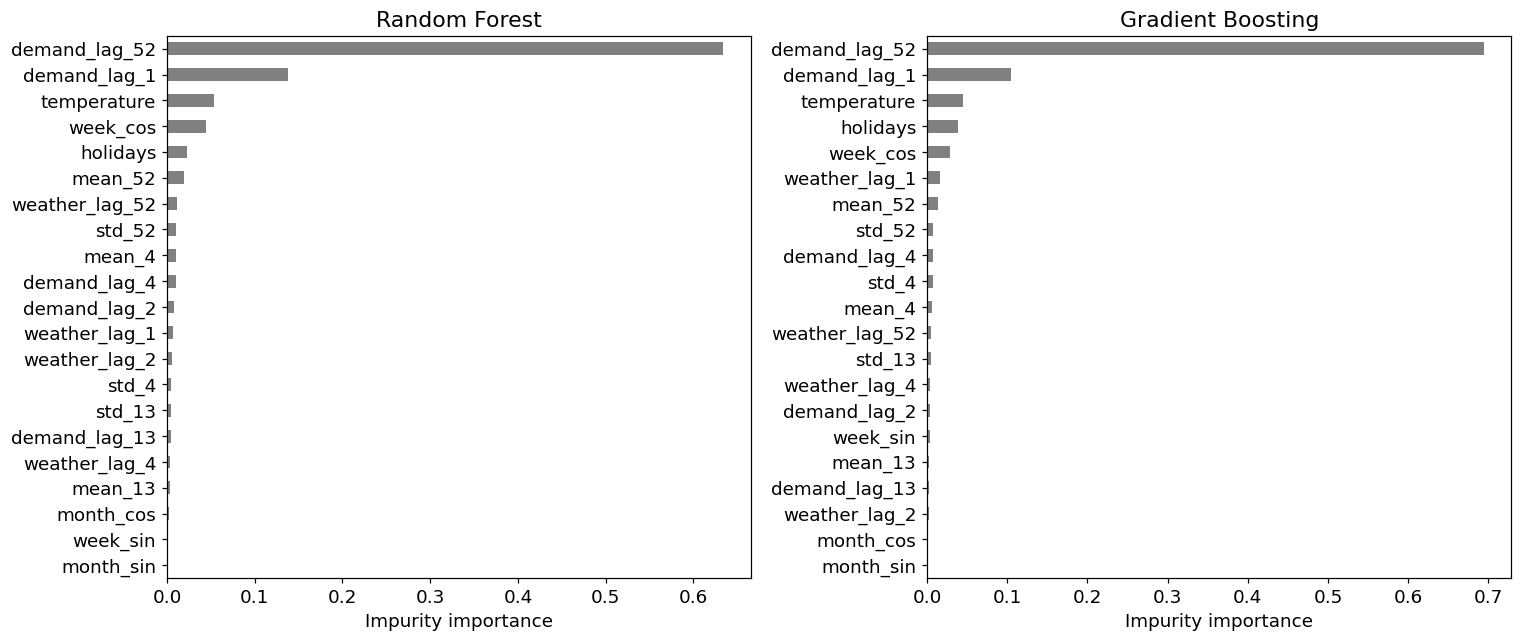

In [15]:
# This cell measures the effects of weather and holiday features.
ablations = {"Full": set(), "No weather": {"temperature", *[f"weather_lag_{lag}" for lag in WEATHER_LAGS]},
             "No holidays": {"holidays"},
             "Load and calendar": {"temperature", "holidays", *[f"weather_lag_{lag}" for lag in WEATHER_LAGS]}}
ablation_rows = []
for name, experiment in tree_models.items():
    if experiment.mode != "Operational":
        continue
    for label, removed in ablations.items():
        losses = []
        for start, end in validation_windows(len(week_train)):
            past_y, future_y = week_train.iloc[:start], week_train.iloc[start:end]
            past_x = weather_train.loc[past_y.index]
            training = regression_data(past_y, past_x)
            columns = [column for column in experiment.columns if column not in removed]
            reduced = clone(experiment.model).fit(training[columns], training.target)
            prediction = forecast_tree(reduced, past_y, past_x.temperature,
                                       weather_normal(past_x.temperature, future_y.index),
                                       weather_train.loc[future_y.index, "holidays"], columns)
            losses.append(float(np.sqrt(mean_squared_error(future_y, prediction))))
        ablation_rows.append({"Model": name, "Features": label, "Validation_RMSE": np.mean(losses),
                              "Folds": len(losses), "Test_used_for_selection": False})
display(write_table(pd.DataFrame(ablation_rows), "covariate_ablation"))
fig, axes = plt.subplots(1, 2, figsize=(14, 6))
for ax, family in zip(axes, ("Random Forest", "Gradient Boosting")):
    experiment = tree_models[f"{family} operational"]
    pd.Series(experiment.model.feature_importances_, index=experiment.columns).sort_values().plot.barh(ax=ax, color="gray")
    ax.set(title=family, xlabel="Impurity importance")
save_figure("08_tree_importance")


## 16. LSTM model tools

The LSTM uses recent hourly demand to predict blocks of future hours. Block recursion extends those predictions across the holdout.


In [16]:
# This cell defines the hourly LSTM and its forecast helpers.
import tensorflow as tf
from tensorflow.keras import Sequential
from tensorflow.keras.layers import Dense, Dropout, Input, LSTM
from tensorflow.keras.optimizers import Adam

tf.get_logger().setLevel("ERROR")
tf.keras.utils.set_random_seed(cfg.seed)
try:
    tf.config.experimental.enable_op_determinism()
except (AttributeError, RuntimeError):
    pass


def hourly_windows(values, lookback, horizon=168, stride=48):
    """Builds hourly input windows and matching target blocks."""
    windows = np.lib.stride_tricks.sliding_window_view(np.asarray(values, dtype=np.float32), lookback + horizon)[::stride]
    return windows[:, :lookback, None].copy(), windows[:, lookback:].copy()


def neural_model(specification):
    """Creates and compiles an LSTM with the specified settings."""
    model = Sequential([Input((specification["lookback"], 1))])
    for number, units in enumerate(specification["layers"]):
        model.add(LSTM(units, return_sequences=number < len(specification["layers"]) - 1))
        model.add(Dropout(specification["dropout"]))
    model.add(Dense(cfg.hourly_week))
    model.compile(optimizer=Adam(learning_rate=specification["rate"]), loss="mse")
    return model


def neural_recursion(network, history, lookback, steps):
    """Forecasts hourly blocks using earlier predictions as inputs."""
    values = np.asarray(history, dtype=np.float32).tolist()
    forecast = []
    predict_block = tf.function(lambda batch: network(batch, training=False))
    while len(forecast) < steps:
        window = np.asarray(values[-lookback:], dtype=np.float32).reshape(1, lookback, 1)
        block = predict_block(window).numpy().reshape(-1)
        forecast.extend(block.tolist())
        values.extend(block.tolist())
    return np.asarray(forecast[:steps], dtype=float)


neural_options = [
    {"lookback": 168, "layers": [32], "dropout": 0.1, "rate": 0.001, "batch": 64},
    {"lookback": 168, "layers": [64], "dropout": 0.1, "rate": 0.001, "batch": 64},
    {"lookback": 336, "layers": [64, 32], "dropout": 0.2, "rate": 0.001, "batch": 64},
    {"lookback": 336, "layers": [48, 24], "dropout": 0.2, "rate": 0.0005, "batch": 32},
    {"lookback": 336, "layers": [32, 16], "dropout": 0.3, "rate": 0.0005, "batch": 64},
    {"lookback": 504, "layers": [64, 32], "dropout": 0.2, "rate": 0.001, "batch": 64},
    {"lookback": 336, "layers": [128, 64], "dropout": 0.2, "rate": 0.001, "batch": 64},
]

## 17. LSTM tuning

Validation compares seven LSTM configurations without using the final holdout. Early stopping limits training when recursive forecast error stops improving.


In [17]:
# This cell compares LSTM settings on the validation period.
lstm_started = time.monotonic()
cut = int(len(hour_train) * 0.85) // cfg.hourly_week * cfg.hourly_week
neural_train, neural_valid = hour_train.iloc[:cut], hour_train.iloc[cut:]
search_scaler = StandardScaler().fit(neural_train.to_numpy().reshape(-1, 1))
scaled_search = search_scaler.transform(neural_train.to_numpy().reshape(-1, 1)).ravel()
neural_records, neural_histories = [], {}
for number, specification in enumerate(neural_options):
    tf.keras.backend.clear_session()
    tf.keras.utils.set_random_seed(cfg.seed + number)
    x, y = hourly_windows(scaled_search, specification["lookback"])
    network = neural_model(specification)
    best_loss, best_epoch, patience = np.inf, 0, 0
    trace = []
    print(f"LSTM candidate {number + 1}/{len(neural_options)}", flush=True)
    for epoch in range(1, cfg.lstm_epochs + 1):
        fitted = network.fit(x, y, epochs=1, batch_size=specification["batch"], shuffle=False, verbose=0)
        prediction = neural_recursion(network, scaled_search, specification["lookback"], len(neural_valid))
        prediction = search_scaler.inverse_transform(prediction.reshape(-1, 1)).ravel()
        loss = float(np.sqrt(mean_squared_error(neural_valid, prediction)))
        trace.append({"Epoch": epoch, "Training_loss": fitted.history["loss"][-1], "Validation_RMSE": loss})
        if loss < best_loss - 1e-6:
            best_loss, best_epoch, patience = loss, epoch, 0
        else:
            patience += 1
        if patience >= cfg.lstm_patience:
            break
    neural_records.append({"Candidate": number, "Validation_RMSE": best_loss,
                           "Epochs": best_epoch, **specification})
    neural_histories[number] = pd.DataFrame(trace)
    del network, x, y
    gc.collect()
neural_search = pd.DataFrame(neural_records).sort_values("Validation_RMSE").reset_index(drop=True)
best_neural = int(neural_search.iloc[0].Candidate)
neural_spec = neural_options[best_neural]
neural_epochs = int(neural_search.iloc[0].Epochs)
if not np.isfinite(neural_search.iloc[0].Validation_RMSE) or neural_epochs < 1:
    raise RuntimeError("LSTM tuning did not produce a finite validation score")
display(write_table(neural_search, "lstm_tuning"))
write_table(neural_histories[best_neural], "lstm_selected_learning_curve")

LSTM candidate 1/7


E0000 00:00:1793766116.312687      50 node_def_util.cc:682] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_15}}
E0000 00:00:1793766121.653502      50 node_def_util.cc:682] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),

LSTM candidate 2/7


E0000 00:00:1793766126.942599      50 node_def_util.cc:682] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_15}}


LSTM candidate 3/7


E0000 00:00:1793766132.326727      50 node_def_util.cc:682] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_15}}
E0000 00:00:1793766137.448338      50 node_def_util.cc:682] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),

... (6 outputs left out)

LSTM candidate 7/7


E0000 00:00:1793766200.629987      50 node_def_util.cc:682] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_15}}
E0000 00:00:1793766206.045558      50 node_def_util.cc:682] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),

,Candidate,Validation_RMSE,Epochs,lookback,layers,dropout,rate,batch
0,5,5735.225718,10,504,"[64, 32]",0.2,0.0010,64
1,2,5892.025476,9,336,"[64, 32]",0.2,0.0010,64
2,3,5988.998036,16,336,"[48, 24]",0.2,0.0005,32
3,4,6006.932819,30,336,"[32, 16]",0.3,0.0005,64
4,6,6309.309071,4,336,"[128, 64]",0.2,0.0010,64
5,1,6448.891167,5,168,[64],0.1,0.0010,64
6,0,7056.694277,7,168,[32],0.1,0.0010,64


,Epoch,Training_loss,Validation_RMSE
0,1,0.980360,9494.309682
1,2,0.897818,8535.208328
2,3,0.752876,7637.243744
3,4,0.634214,6983.076981
4,5,0.557378,7002.149494
5,6,0.510545,7437.151032
6,7,0.487612,7632.706273
7,8,0.470340,7552.380612
8,9,0.459297,5969.178835
9,10,0.445804,5735.225718


## 18. Hourly LSTM forecast

The selected LSTM is refitted on the training period and scored at hourly resolution. Weekly aggregation supports comparisons with the weekly models.


In [18]:
# This cell fits the selected LSTM and forecasts hourly demand.
hour_scaler = StandardScaler().fit(hour_train.to_numpy().reshape(-1, 1))
scaled_hours = hour_scaler.transform(hour_train.to_numpy().reshape(-1, 1)).ravel()
x, y = hourly_windows(scaled_hours, neural_spec["lookback"])
tf.keras.backend.clear_session()
tf.keras.utils.set_random_seed(cfg.seed)
final_network = neural_model(neural_spec)
training_history = final_network.fit(x, y, epochs=neural_epochs, batch_size=neural_spec["batch"],
                                     shuffle=False, verbose=0)
scaled_forecast = neural_recursion(final_network, scaled_hours, neural_spec["lookback"], len(hour_test))
neural_forecast = hour_scaler.inverse_transform(scaled_forecast.reshape(-1, 1)).ravel()
hourly_book.add("LSTM", neural_forecast, "Operational")
hourly_book.add("Weekly seasonal naive", np.resize(hour_train.iloc[-168:].to_numpy(), len(hour_test)), "Operational")
hourly_book.add("Annual seasonal naive", np.resize(hour_train.iloc[-8736:].to_numpy(), len(hour_test)), "Operational")
weekly_neural = complete_means(hourly_book.predictions["LSTM"], cfg.week_rule, 168).reindex(week_test.index)
weekly_book.add("LSTM weekly aggregate", weekly_neural, "Operational")
final_network.save(paths["models"] / "lstm.keras")
joblib.dump(hour_scaler, paths["models"] / "hour_scaler.joblib")
(paths["models"] / "lstm_configuration.json").write_text(json.dumps({"specification": neural_spec,
    "epochs": neural_epochs, "scaler_end": str(hour_train.index.max()), "seed": cfg.seed}, indent=2))
write_table(pd.DataFrame(training_history.history), "lstm_training")
display(write_table(hourly_book.scores("Annual seasonal naive"), "hourly_scores"))
del x, y


,Model,Frequency,Protocol,N,RMSE,MAE,MAPE_percent,sMAPE_percent,MASE,RMSE_improvement_percent
0,Annual seasonal naive,Hourly,Operational,17544,4502.721534,3073.118331,5.875336,5.643549,1.334301,0.000000
1,Weekly seasonal naive,Hourly,Operational,17544,5673.711282,4411.524567,8.349853,8.074608,1.915416,-26.006266
2,LSTM,Hourly,Operational,17544,8096.033333,6547.307075,12.450174,11.900550,2.842740,-79.803110


## 19. LSTM stability and plots

An additional seed shows how training variability affects hourly forecast errors. Plots show both the long horizon and a short hourly view.


E0000 00:00:1793766214.436122      50 node_def_util.cc:682] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_15}}


LSTM stages elapsed: 1.9 minutes


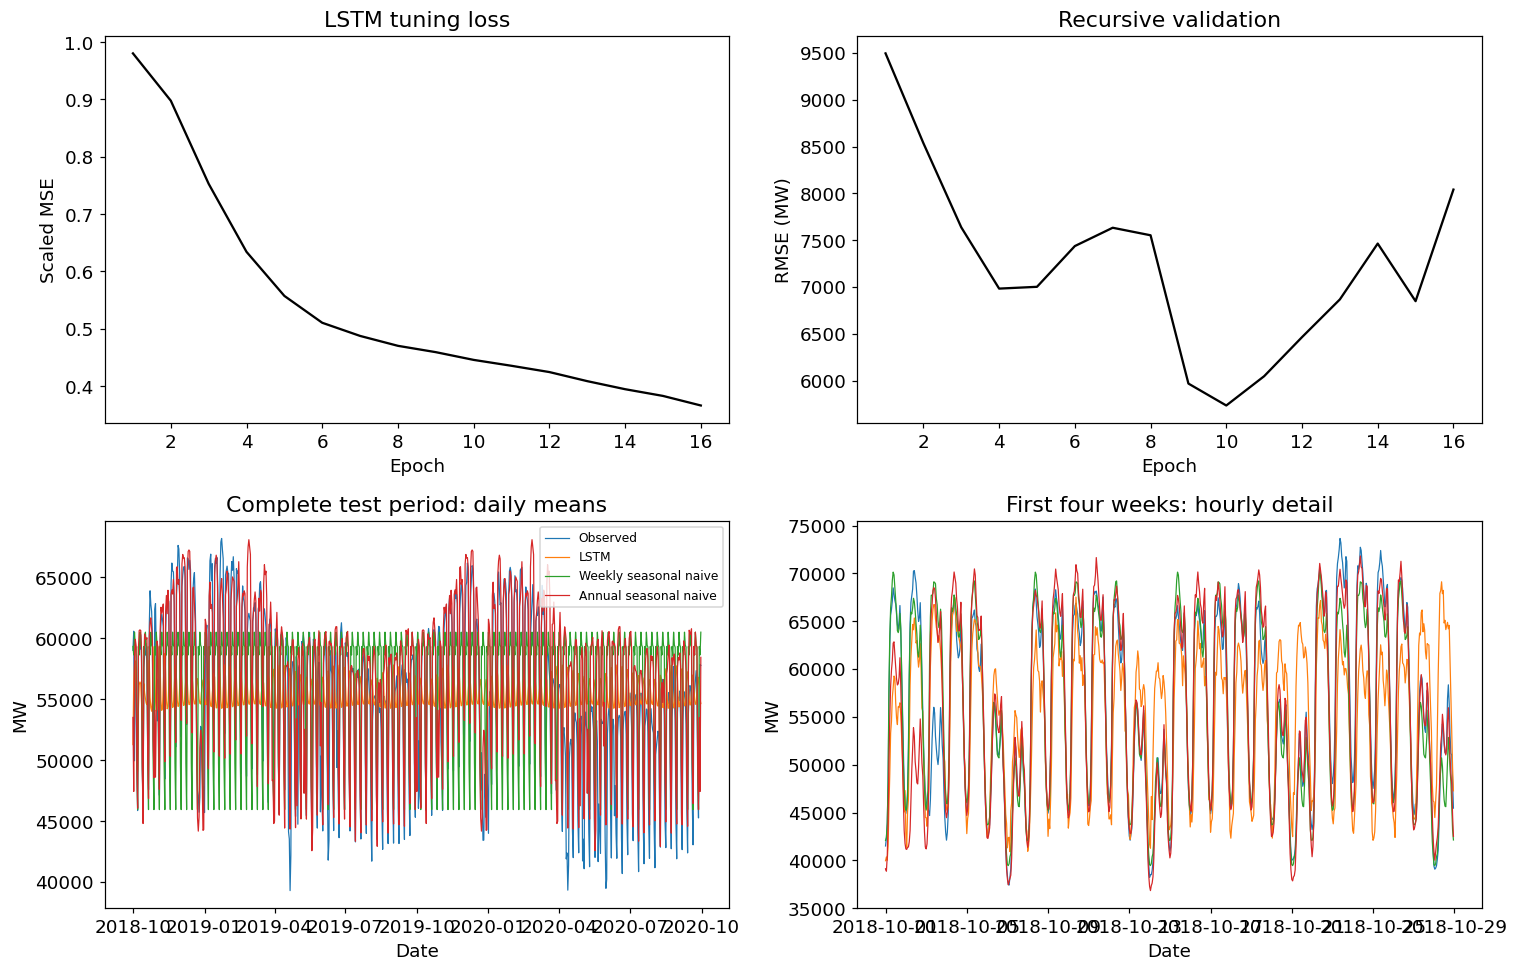

In [19]:
# This cell checks LSTM stability across seeds and plots the results.
seed_results = [{"Seed": cfg.seed, **error_scores(hour_test, hourly_book.predictions["LSTM"], hour_train, 168)}]
for seed in (cfg.seed + 1,):
    tf.keras.backend.clear_session()
    tf.keras.utils.set_random_seed(seed)
    x, y = hourly_windows(scaled_hours, neural_spec["lookback"])
    alternative = neural_model(neural_spec)
    alternative.fit(x, y, epochs=neural_epochs, batch_size=neural_spec["batch"], shuffle=False, verbose=0)
    values = neural_recursion(alternative, scaled_hours, neural_spec["lookback"], len(hour_test))
    values = hour_scaler.inverse_transform(values.reshape(-1, 1)).ravel()
    seed_results.append({"Seed": seed, **error_scores(hour_test, pd.Series(values, index=hour_test.index), hour_train, 168)})
    del alternative, x, y
    gc.collect()
write_table(pd.DataFrame(seed_results), "lstm_seed_stability")
print(f"LSTM stages elapsed: {(time.monotonic() - lstm_started) / 60:.1f} minutes")
fig, axes = plt.subplots(2, 2, figsize=(14, 9))
trace = neural_histories[best_neural]
axes[0, 0].plot(trace.Epoch, trace.Training_loss, color="black")
axes[0, 0].set(title="LSTM tuning loss", xlabel="Epoch", ylabel="Scaled MSE")
axes[0, 1].plot(trace.Epoch, trace.Validation_RMSE, color="black")
axes[0, 1].set(title="Recursive validation", xlabel="Epoch", ylabel="RMSE (MW)")
for name, prediction in {"Observed": hour_test, **hourly_book.predictions}.items():
    axes[1, 0].plot(prediction.resample("D").mean(), label=name, linewidth=0.8)
    axes[1, 1].plot(prediction.iloc[:168 * 4], label=name, linewidth=0.8)
axes[1, 0].set(title="Complete test period: daily means", ylabel="MW", xlabel="Date")
axes[1, 1].set(title="First four weeks: hourly detail", ylabel="MW", xlabel="Date")
axes[1, 0].legend(fontsize=8)
save_figure("09_lstm_results")

## 20. Model comparison and uncertainty

Common metrics compare forecasts against seasonal persistence. Interval coverage and paired resampling describe different aspects of uncertainty.


In [20]:
# This cell compares model scores and forecasts uncertainty.
weekly_scores = weekly_book.scores("Seasonal naive")
display(write_table(weekly_scores, "weekly_scores"))
interval_rows = []
for name, bounds in weekly_book.intervals.items():
    for start, end in [(0, len(week_test)), (0, 13), (13, 26), (26, 52), (52, len(week_test))]:
        actual = week_test.iloc[start:end].to_numpy()
        low, high = bounds.iloc[start:end].to_numpy().T
        score = high - low + 40 * (low - actual) * (actual < low) + 40 * (actual - high) * (actual > high)
        interval_rows.append({"Model": name, "First_week": start + 1, "Last_week": end,
                              "Nominal_coverage": 0.95, "Coverage": np.mean((actual >= low) & (actual <= high)),
                              "Mean_width_MW": np.mean(high - low), "Interval_score": np.mean(score)})
interval_scores = write_table(pd.DataFrame(interval_rows), "interval_scores")
display(interval_scores.loc[interval_scores.Last_week.eq(len(week_test)) & interval_scores.First_week.eq(1)])


def paired_gain(actual, reference, candidate, block=8, draws=1000):
    """Estimates uncertainty in RMSE gain with paired block resampling."""
    y, a, b = (np.asarray(values, dtype=float) for values in (actual, reference, candidate))
    generator = np.random.default_rng(cfg.seed)
    gains = []
    for _ in range(draws):
        starts = generator.integers(0, len(y), math.ceil(len(y) / block))
        rows = np.concatenate([(start + np.arange(block)) % len(y) for start in starts])[:len(y)]
        gains.append(np.sqrt(np.mean((y[rows] - a[rows]) ** 2)) - np.sqrt(np.mean((y[rows] - b[rows]) ** 2)))
    return np.quantile(gains, [0.025, 0.975])


uncertainty = []
reference = weekly_book.predictions["Seasonal naive"]
for name, prediction in weekly_book.predictions.items():
    if name == "Seasonal naive":
        continue
    low, high = paired_gain(week_test, reference, prediction, draws=cfg.bootstrap_draws)
    gain = np.sqrt(mean_squared_error(week_test, reference)) - np.sqrt(mean_squared_error(week_test, prediction))
    uncertainty.append({"Model": name, "RMSE_gain_MW": gain, "Lower_95": low, "Upper_95": high,
                        "Protocol": weekly_book.protocols[name], "Evaluation_only": True})
display(write_table(pd.DataFrame(uncertainty), "benchmark_gain_bootstrap"))


,Model,Frequency,Protocol,N,RMSE,MAE,MAPE_percent,sMAPE_percent,MASE,RMSE_improvement_percent
0,SARIMA,Weekly,Operational,104,2404.993023,1846.335963,3.509924,3.425454,1.366580,19.518302
1,Random Forest conditional,Weekly,Conditional,104,2753.002203,2119.467253,4.064185,3.937071,1.568740,7.872376
2,Random Forest operational,Weekly,Operational,104,2894.919145,2280.958934,4.351389,4.212872,1.688269,3.123208
3,Seasonal naive,Weekly,Operational,104,2988.248349,2288.489240,4.356128,4.206690,1.693843,0.000000
4,Gradient Boosting operational,Weekly,Operational,104,2999.886267,2329.772917,4.459367,4.300683,1.724399,-0.389456
5,Gradient Boosting conditional,Weekly,Conditional,104,3015.667816,2242.089001,4.326221,4.162915,1.659499,-0.917577
6,SARIMAX holidays,Weekly,Operational,104,3731.908670,3061.829030,5.803706,5.554577,2.266236,-24.886162
7,SARIMAX matched load-only,Weekly,Operational,104,3851.807080,3155.484040,5.995661,5.732994,2.335556,-28.898493
8,SARIMAX temperature + holidays,Weekly,Conditional,104,4027.442522,3296.608612,6.256234,5.965363,2.440010,-34.776031
9,SARIMAX climatology + holidays,Weekly,Operational,104,4076.724512,3389.896745,6.414577,6.118883,2.509058,-36.425224


,Model,First_week,Last_week,Nominal_coverage,Coverage,Mean_width_MW,Interval_score
0,SARIMA,1,104,0.95,0.875000,7280.295745,13896.055618
5,SARIMAX matched load-only,1,104,0.95,0.509615,5630.040981,46942.171922
10,SARIMAX holidays,1,104,0.95,0.432692,4696.248385,53080.740759
15,SARIMAX temperature,1,104,0.95,0.528846,6605.608963,42968.038661
20,SARIMAX temperature + holidays,1,104,0.95,0.538462,6292.778312,39646.833523
25,SARIMAX climatology,1,104,0.95,0.519231,6605.608963,43800.381506
30,SARIMAX climatology + holidays,1,104,0.95,0.528846,6292.778312,40255.525665


,Model,RMSE_gain_MW,Lower_95,Upper_95,Protocol,Evaluation_only
0,Mean,-1413.810436,-2285.083651,-725.615936,Operational,True
1,Naive,-1487.518736,-2203.248457,-919.285221,Operational,True
2,Drift,-1478.246040,-2200.420709,-903.470786,Operational,True
3,SARIMA,583.255326,195.213333,897.654388,Operational,True
4,SARIMAX matched load-only,-863.558731,-1178.945237,-531.102761,Operational,True
5,SARIMAX holidays,-743.660321,-1056.247734,-375.418235,Operational,True
6,SARIMAX temperature,-1195.838604,-1554.520475,-775.100213,Conditional,True
7,SARIMAX temperature + holidays,-1039.194174,-1390.612454,-583.093237,Conditional,True
8,SARIMAX climatology,-1253.673562,-1603.805044,-889.370355,Operational,True
9,SARIMAX climatology + holidays,-1088.476163,-1429.013710,-678.788152,Operational,True


### COVID period comparison

The date split shows whether forecast errors changed around March 2020. It compares periods without attributing the change to lockdown measures.


In [21]:
# This cell compares errors before and after the March 2020 COVID cutoff.
covid_start = pd.Timestamp("2020-03-15")
rows = []
for name, pred in weekly_book.predictions.items():
    for label, mask in [("Pre-COVID", week_test.index < covid_start),
                        ("COVID period", week_test.index >= covid_start)]:
        rows.append({"Model": name, "Period": label,
                     **error_scores(week_test[mask], pred[mask], week_train, 52)})
display(write_table(pd.DataFrame(rows), "covid_split_scores"))


,Model,Period,RMSE,MAE,MAPE_percent,sMAPE_percent,MASE
0,Mean,Pre-COVID,3963.936258,3320.291864,5.804398,5.870577,2.457539
1,Mean,COVID period,5371.910792,5004.207569,10.016252,9.468259,3.703902
2,Naive,Pre-COVID,3869.956689,3262.601825,5.744757,5.767517,2.414840
3,Naive,COVID period,5753.969263,5398.352833,10.799991,10.171112,3.995632
4,Seasonal naive,Pre-COVID,1875.254545,1472.654762,2.646562,2.609857,1.089997
5,Seasonal naive,COVID period,4788.412240,4398.405993,8.777421,8.336432,3.255514
6,Drift,Pre-COVID,3871.332582,3263.707962,5.745366,5.769489,2.415658
7,Drift,COVID period,5725.666064,5369.054519,10.741832,10.119055,3.973947
8,SARIMA,Pre-COVID,1704.134858,1308.134481,2.351081,2.335054,0.968226
9,SARIMA,COVID period,3637.588434,3238.236349,6.506932,6.245455,2.396805


## 21. Forecast figures

Grouped panels make the forecast paths easier to compare with observed demand. Shading identifies the selected March–June 2020 window.


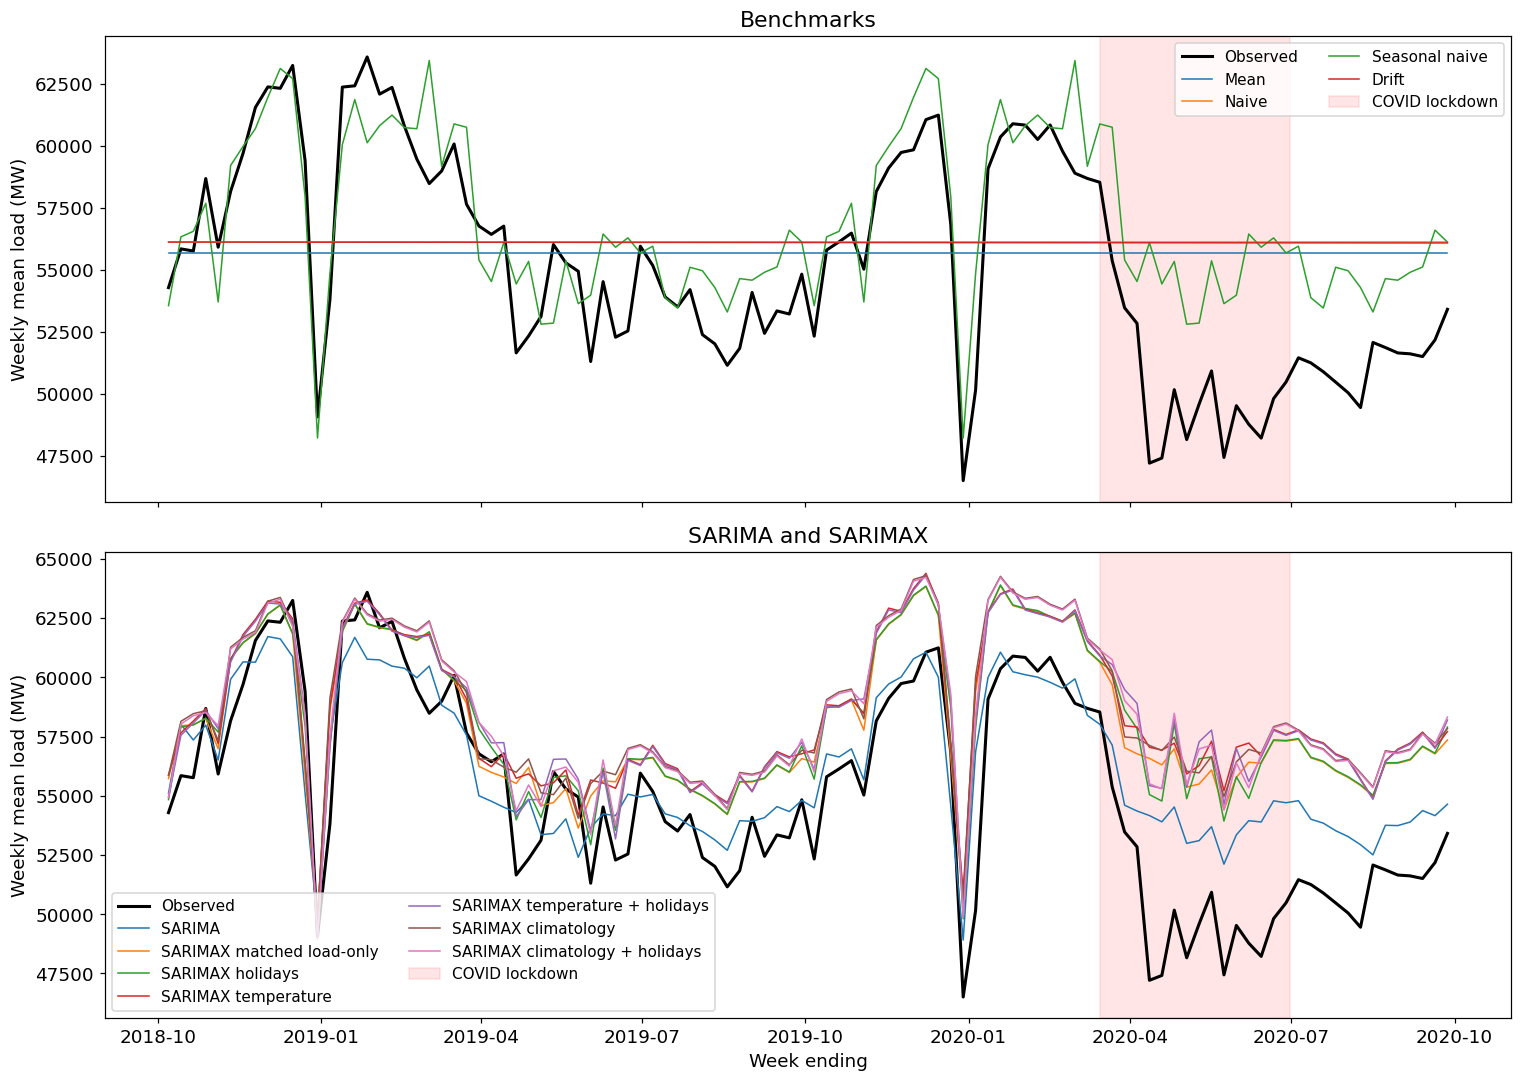

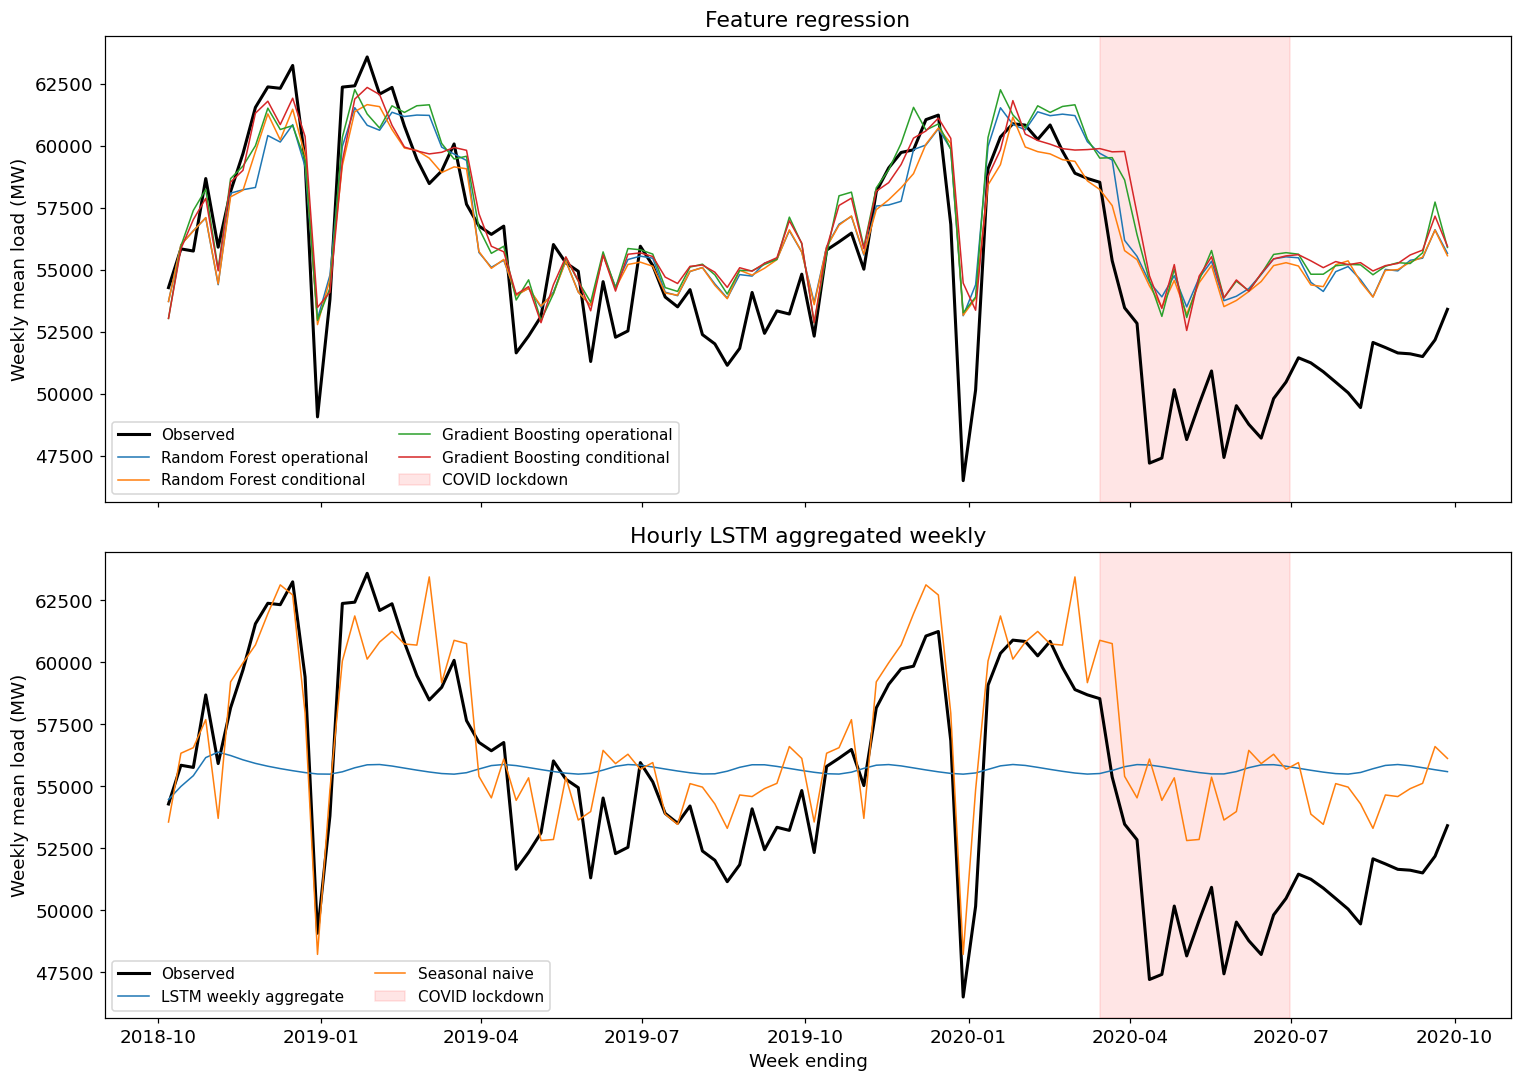

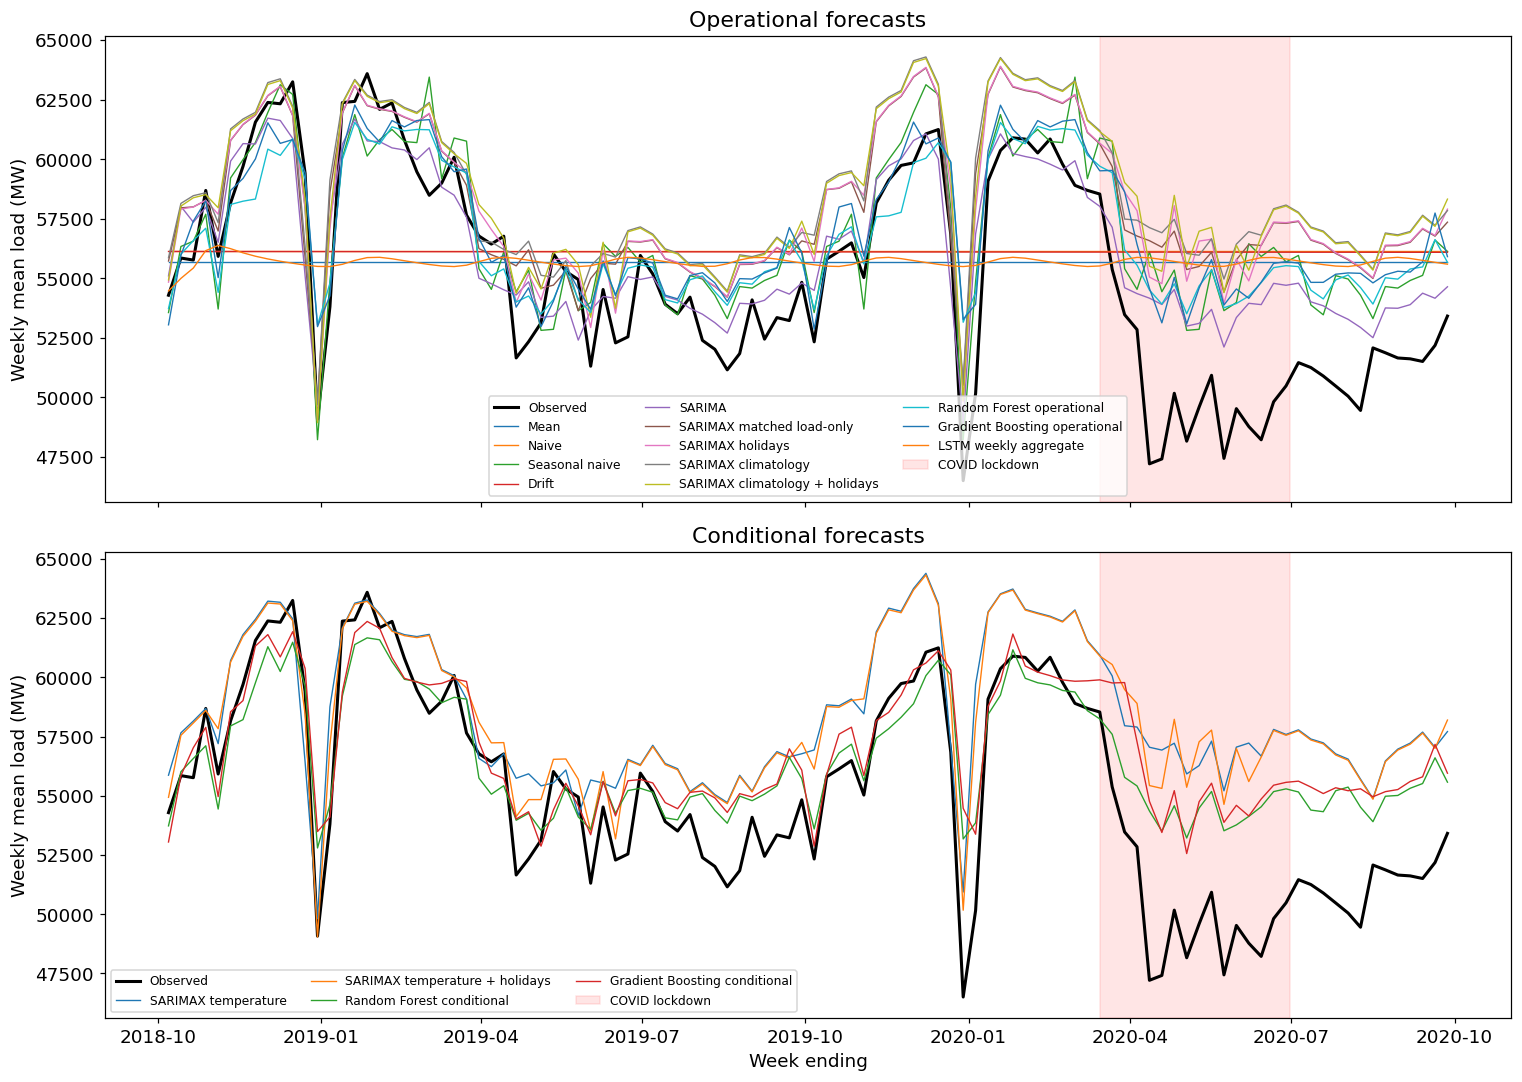

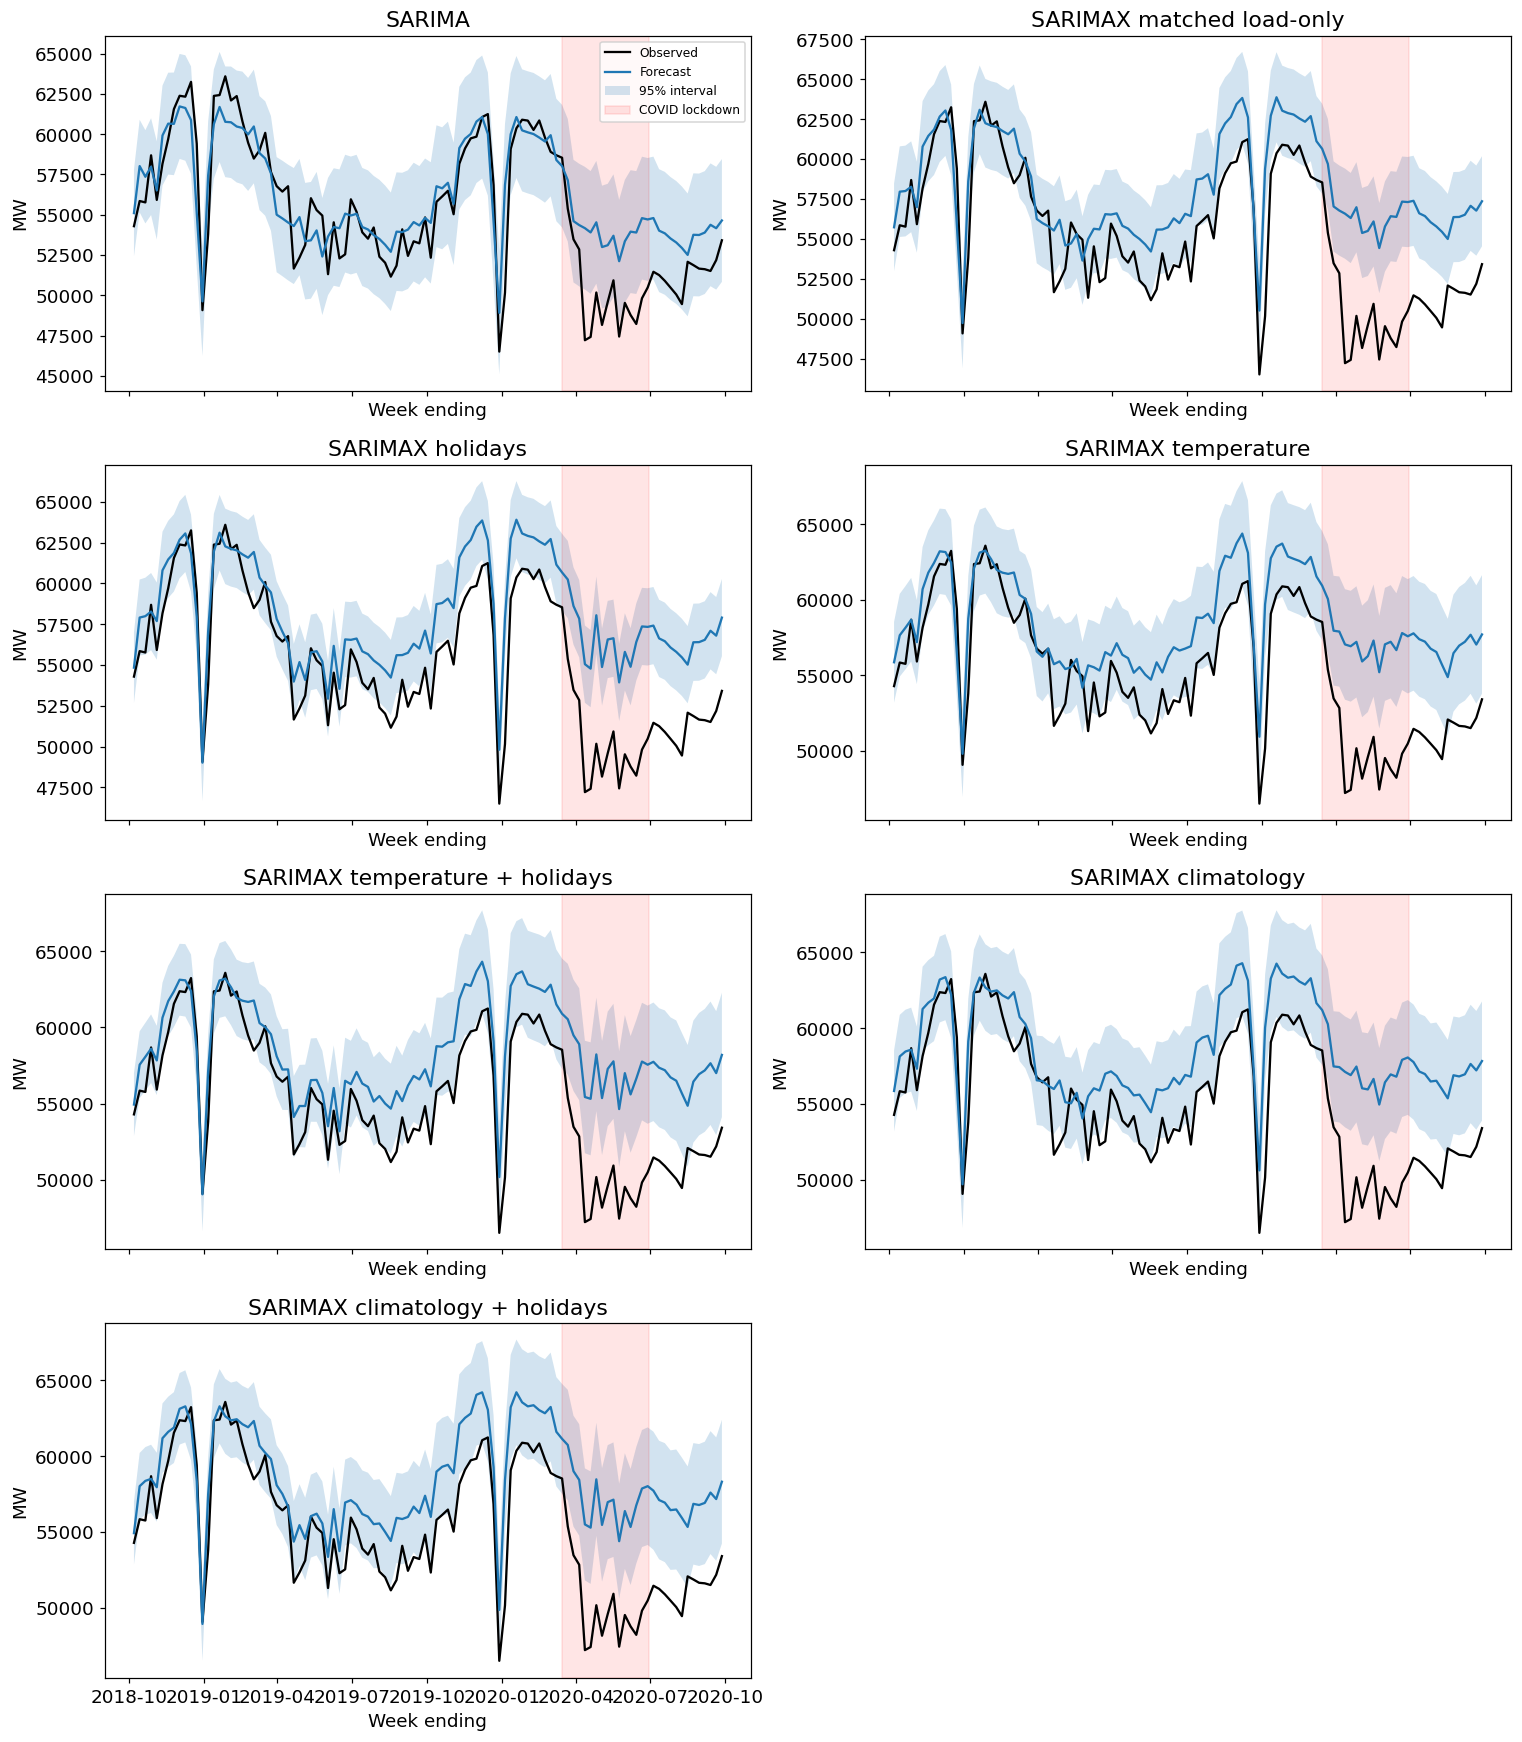

In [22]:
# This cell plots the forecasts and prediction intervals.
groups = {
    "Benchmarks": ["Mean", "Naive", "Seasonal naive", "Drift"],
    "SARIMA and SARIMAX": ["SARIMA", "SARIMAX matched load-only", *state_scenarios],
    "Feature regression": list(tree_models),
    "Hourly LSTM aggregated weekly": ["LSTM weekly aggregate", "Seasonal naive"],
}
family_groups = list(groups.items())
for suffix, panels in (("a", family_groups[:2]), ("b", family_groups[2:])):
    fig, axes = plt.subplots(2, 1, figsize=(14, 10), sharex=True)
    for ax, (title, names) in zip(axes, panels):
        ax.plot(week_test, color="black", linewidth=2, label="Observed")
        for name in names:
            ax.plot(weekly_book.predictions[name], label=name, linewidth=1)
        ax.set(title=title, ylabel="Weekly mean load (MW)")
        ax.axvspan(pd.Timestamp("2020-03-15"), pd.Timestamp("2020-06-30"),
                   color="red", alpha=0.1, label="COVID lockdown")
        ax.legend(fontsize=10, ncol=2)
    axes[-1].set_xlabel("Week ending")
    save_figure(f"10{suffix}_model_family_forecasts")
fig, axes = plt.subplots(2, 1, figsize=(14, 10), sharex=True)
for ax, protocol in zip(axes, ("Operational", "Conditional")):
    ax.plot(week_test, color="black", linewidth=2, label="Observed")
    for name, prediction in weekly_book.predictions.items():
        if weekly_book.protocols[name] == protocol:
            ax.plot(prediction, label=name, linewidth=0.9)
    ax.set(title=f"{protocol} forecasts", ylabel="Weekly mean load (MW)")
    ax.axvspan(pd.Timestamp("2020-03-15"), pd.Timestamp("2020-06-30"),
               color="red", alpha=0.1, label="COVID lockdown")
    ax.legend(fontsize=8, ncol=3)
axes[-1].set_xlabel("Week ending")
save_figure("11_forecasts_by_availability")
interval_panels = math.ceil(len(weekly_book.intervals) / 2)
fig, axes = plt.subplots(interval_panels, 2, figsize=(14, 4 * interval_panels), sharex=True)
for ax in axes.flat[len(weekly_book.intervals):]:
    ax.set_visible(False)
for ax, (name, bounds) in zip(axes.flat, weekly_book.intervals.items()):
    ax.plot(week_test, color="black", label="Observed")
    ax.plot(weekly_book.predictions[name], label="Forecast")
    ax.fill_between(bounds.index, bounds.lower, bounds.upper, alpha=0.2, label="95% interval")
    ax.axvspan(pd.Timestamp("2020-03-15"), pd.Timestamp("2020-06-30"),
               color="red", alpha=0.1, label="COVID lockdown")
    ax.set(title=name, xlabel="Week ending", ylabel="MW")
axes[0, 0].legend(fontsize=8)
save_figure("12_prediction_intervals")

## 22. Horizon and complexity evidence

Horizon summaries show how errors change further from the forecast origin. Model trade-offs put accuracy alongside interpretability and maintenance.


In [23]:
# This cell compares errors by horizon and summarizes model trade-offs.
horizon_rows = []
for name, prediction in weekly_book.predictions.items():
    for start, end in [(0, 13), (13, 26), (26, 52), (52, len(week_test))]:
        truth, estimate = week_test.iloc[start:end], prediction.iloc[start:end]
        horizon_rows.append({"Model": name, "First_week": start + 1, "Last_week": end,
                             **error_scores(truth, estimate, week_train, 52)})
write_table(pd.DataFrame(horizon_rows), "horizon_scores")
tradeoffs = pd.DataFrame([
    ["Seasonal naive", "Annual persistence", "High", "Requires separate calibration", "Low"],
    ["SARIMAX", "AR/MA coefficients and covariates", "Moderate", "Parametric intervals", "Moderate"],
    ["Tree ensembles", "Lagged, weather and calendar features", "Moderate", "No native calibrated intervals", "Moderate"],
    ["LSTM", "Hourly demand sequences", "Low", "No calibrated intervals", "High"],
], columns=["Family", "Mechanism", "Interpretability", "Uncertainty", "Maintenance"])
write_table(tradeoffs, "model_tradeoffs")
state_baseline = weekly_scores.set_index("Model").loc["SARIMAX matched load-only", "RMSE"]
covariate_test = weekly_scores.loc[weekly_scores.Model.isin(state_scenarios)].copy()
covariate_test["Gain_over_matched_load_only_MW"] = state_baseline - covariate_test.RMSE
write_table(covariate_test, "sarimax_covariate_comparison")
operational = weekly_scores.loc[weekly_scores.Protocol.eq("Operational")].copy()
write_table(operational, "operational_comparison")

,Model,Frequency,Protocol,N,RMSE,MAE,MAPE_percent,sMAPE_percent,MASE,RMSE_improvement_percent
0,SARIMA,Weekly,Operational,104,2404.993023,1846.335963,3.509924,3.425454,1.366580,19.518302
2,Random Forest operational,Weekly,Operational,104,2894.919145,2280.958934,4.351389,4.212872,1.688269,3.123208
3,Seasonal naive,Weekly,Operational,104,2988.248349,2288.489240,4.356128,4.206690,1.693843,0.000000
4,Gradient Boosting operational,Weekly,Operational,104,2999.886267,2329.772917,4.459367,4.300683,1.724399,-0.389456
6,SARIMAX holidays,Weekly,Operational,104,3731.908670,3061.829030,5.803706,5.554577,2.266236,-24.886162
7,SARIMAX matched load-only,Weekly,Operational,104,3851.807080,3155.484040,5.995661,5.732994,2.335556,-28.898493
9,SARIMAX climatology + holidays,Weekly,Operational,104,4076.724512,3389.896745,6.414577,6.118883,2.509058,-36.425224
11,SARIMAX climatology,Weekly,Operational,104,4241.921911,3518.328847,6.672319,6.353510,2.604118,-41.953460
12,LSTM weekly aggregate,Weekly,Operational,104,4374.962885,3766.998118,6.936874,6.832718,2.788172,-46.405599
13,Mean,Weekly,Operational,104,4402.058785,3789.845282,6.978857,6.873777,2.805083,-47.312347


## 23. Independent checks

Independent checks verify lag timing and model reloads. Recomputed metrics confirm that exported predictions match the evaluation.


In [24]:
# This cell checks feature timing, saved models, and exported scores.
def validate_feature_provenance():
    """Checks lag timing with a controlled recursive forecast."""
    dates = pd.date_range("2015-01-04", periods=70, freq="W-SUN")
    target = pd.Series(np.arange(70, dtype=float) + 100, index=dates)
    covariates = pd.DataFrame({"temperature": np.arange(70, dtype=float) + 1000,
                               "holidays": 0.0}, index=dates)
    training = regression_data(target, covariates)
    assert training.iloc[-1].demand_lag_1 == 168
    assert training.iloc[-1].weather_lag_52 == 1017
    assert training.iloc[-1].mean_4 == np.mean([165, 166, 167, 168])
    class Recorder:
        """Captures the feature rows supplied during the provenance check."""
        def __init__(self):
            """Starts an empty record of feature rows."""
            self.rows = []
        def predict(self, values):
            """Records its input features and returns a fixed test prediction."""
            self.rows.append(values.copy())
            return np.array([999.0])
    recorder = Recorder()
    dates = pd.date_range(dates[-1] + pd.Timedelta(weeks=1), periods=3, freq="W-SUN")
    weather = pd.Series([10., 11., 12.], index=dates)
    columns = training.columns.drop("target").to_list()
    forecast_tree(recorder, target, covariates.temperature, weather,
                  pd.Series(0., index=dates), columns)
    assert recorder.rows[0].iloc[0].weather_lag_1 == 1069
    assert recorder.rows[1].iloc[0].weather_lag_1 == 10
    assert recorder.rows[1].iloc[0].demand_lag_1 == 999
    return True


validation = [{"Check": "Past-only features and recursive history", "Passed": validate_feature_provenance()}]
expected_candidates = set(sarima_candidates(sarima_grid.to_dict("records")))
assert len(search_orders) == 147
assert {(tuple(row.order), tuple(row.seasonal)) for row in sarima_grid.itertuples()} == expected_candidates
assert len(sarima_grid) == len(expected_candidates)
assert sarima_grid.effective_n.nunique() == 1
assert week_train.index.max() < week_test.index.min()
assert hour_train.index.max() < hour_test.index.min()
for name, experiment in tree_models.items():
    safe = name.lower().replace(" ", "_")
    stored = joblib.load(paths["models"] / f"{safe}.joblib")
    future_weather = normal_test if experiment.mode == "Operational" else weather_test.temperature
    restored = forecast_tree(stored["model"], week_train, weather_train.temperature,
                             future_weather, weather_test.holidays, stored["columns"])
    assert np.allclose(restored, weekly_book.predictions[name])
    validation.append({"Check": f"Saved model: {name}", "Passed": True})
restored_network = tf.keras.models.load_model(paths["models"] / "lstm.keras", compile=False)
restored_scaler = joblib.load(paths["models"] / "hour_scaler.joblib")
scaled = restored_scaler.transform(hour_train.to_numpy().reshape(-1, 1)).ravel()
restored = neural_recursion(restored_network, scaled, neural_spec["lookback"], 336)
restored = restored_scaler.inverse_transform(restored.reshape(-1, 1)).ravel()
assert np.allclose(restored, hourly_book.predictions["LSTM"].iloc[:336], atol=0.1, rtol=1e-6)
validation.append({"Check": "Saved LSTM and training scaler", "Passed": True})
weekly_export = weekly_book.export("weekly")
hourly_export = hourly_book.export("hourly")
reloaded = pd.read_csv(paths["tables"] / "weekly_predictions.csv", index_col=0, parse_dates=True)
for name, prediction in weekly_book.predictions.items():
    assert prediction.index.equals(week_test.index)
    reconstructed = np.sqrt(np.mean((reloaded.actual_MW - reloaded[name]) ** 2))
    recorded = weekly_scores.set_index("Model").loc[name, "RMSE"]
    assert np.isclose(recorded, reconstructed)
validation.append({"Check": "Exported metrics and common test horizon", "Passed": True})
display(write_table(pd.DataFrame(validation), "validation_checks"))

,Check,Passed
0,Past-only features and recursive history,True
1,Saved model: Random Forest operational,True
2,Saved model: Random Forest conditional,True
3,Saved model: Gradient Boosting operational,True
4,Saved model: Gradient Boosting conditional,True
5,Saved LSTM and training scaler,True
6,Exported metrics and common test horizon,True


## 24. Reproducibility exports

The archive collects plots, scores, models, and package versions. The manifest records the data sources, forecast design, and run details.


In [25]:
# This cell exports results, package versions, and run details.
versions = {module: version(module) for module in
            ("numpy", "pandas", "scipy", "matplotlib", "scikit-learn", "statsmodels",
             "requests", "holidays", "joblib", "threadpoolctl")}
for distribution in ("tensorflow", "tensorflow-cpu", "tensorflow-intel", "tensorflow-macos"):
    try:
        versions[distribution] = version(distribution)
        break
    except PackageNotFoundError:
        continue
else:
    raise RuntimeError("Could not identify the installed TensorFlow distribution")
(project / "requirements-ran.txt").write_text("\n".join(f"{name}=={number}" for name, number in versions.items()) + "\n")
manifest = {"dataset": cfg.source_url,
            "elapsed_seconds_before_export": round(time.monotonic() - run_started, 1), "load_field": cfg.load_field,
            "source_start": str(load.index.min()), "source_end": str(load.index.max()),
            "forecast_origin": str(origin), "weekly_test_rows": len(week_test),
            "hourly_test_rows": len(hour_test), "aggregation": "Arithmetic mean load in MW",
            "temperature_location": {"latitude": 52.52, "longitude": 13.41, "timezone": "UTC"},
            "weather_caveat": "Berlin is a representative proxy; observed future weather is conditional",
            "holiday_caveat": "National German holidays only; civil dates aligned to UTC daily bins",
            "sarima_search": search_identity, "package_versions": versions,
            "seed": cfg.seed, "forecast_protocol": "Fixed origin; recursive load inputs",
            "limitations": ["One two-year evaluation origin", "Annual cycle approximated by 52 weeks",
                            "Tree and LSTM intervals not estimated", "Pre-test validation horizons are shorter than the test horizon"]}
(project / "run_manifest.json").write_text(json.dumps(manifest, indent=2))
assets = pd.DataFrame([{"File": str(file.relative_to(project)),
                        "SHA256": hashlib.sha256(file.read_bytes()).hexdigest()}
                       for folder in (paths["tables"], paths["figures"])
                       for file in sorted(folder.glob("*")) if file.is_file()])
assets.to_csv(project / "artifact_manifest.csv", index=False)
archive = base / "German_Demand_Results.zip"
with zipfile.ZipFile(archive, "w", zipfile.ZIP_DEFLATED) as bundle:
    for file in sorted(project.rglob("*")):
        if file.is_file() and not file.name.startswith("search_"):
            bundle.write(file, file.relative_to(project))